In [1]:
import importlib

import read_utils
import plot_utils
import train_utils
from models import glm_sep as glm
from models import hgm_sep as hgm

importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(glm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/VisualStudioCode/Python/MSc_Thesis/data_exploration/worm-2025-fieseler/models/hgm_sep.py'>

In [2]:
import read_utils
import plot_utils
import train_utils
from models import glm_sep as glm
from models import hgm_sep as hgm

import os
import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax

In [3]:
def train_numerical_model(model, splits, X, Y, X_man=None):
	seed = jax.random.PRNGKey(0)

	# Hyperparamters ============
	max_epochs = 100
	min_epochs = 10
	max_patience = 20

	optimizer = optax.adam(1e-3)
	# ===========================

	# training loop =======================================
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	for train, test in splits:
		# splitting and initializing ===============================================================
		X_train, X_test = X[train], X[test]
		if X_man is not None: X_man_train, X_man_test = X_man[train], X_man[test]
		Y_train, Y_test = Y[train], Y[test]

		if X_man is not None:
			params = model.init_params(seed, (X.shape[1], Y.shape[1]), (X_man.shape[1], Y.shape[1]))
		else:
			params = model.init_params(seed, (X.shape[1], Y.shape[1]))
		opt_state = optimizer.init(params)
		# ==========================================================================================

		if X_man is not None:
			losses = [model.loss_fn(params, X_test, X_man_test, Y_test).item()]
			losses_tr = [model.loss_fn(params, X_train, X_man_train, Y_train).item()]
		else:
			losses = [model.loss_fn(params, X_test, Y_test).item()]
			losses_tr = [model.loss_fn(params, X_train, Y_train).item()]

		best_params = params
		best_loss = 1.1
		best_loss_tr = 1.1

		patience = 0
		for epoch in range(max_epochs):
			if X_man is not None:
				params, opt_state = model.update(optimizer.update, opt_state, params, X_train, X_man_train, Y_train)
				loss = model.loss_fn(params, X_test, X_man_test, Y_test).item()
				loss_tr = model.loss_fn(params, X_train, X_man_train, Y_train).item()
			else:
				params, opt_state = model.update(optimizer.update, opt_state, params, X_train, Y_train)
				loss = model.loss_fn(params, X_test, Y_test).item()
				loss_tr = model.loss_fn(params, X_train, Y_train).item()

			# early stopping ================
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					losses_tr.append(loss_tr)
					best_loss = loss
					best_loss_tr = loss_tr
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses_padding = [best_loss for _ in range(max_epochs - len(losses) + 1)]
						losses = losses + losses_padding
						losses_tr_padding = [best_loss_tr for _ in range(max_epochs - len(losses_tr) + 1)]
						losses_tr = losses_tr + losses_tr_padding
						break
					losses.append(loss)
					losses_tr.append(loss_tr)
			# ===============================
			else:
				losses.append(loss)
				losses_tr.append(loss_tr)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)

		# predicting and scoring ========================================================================
		if X_man is not None:
			Y_pred = model.predict(best_params['W1'], best_params['W2'], X_test, X_man_test)
		else:
			Y_pred = model.predict(best_params['W'], X_test)

		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# =====================================================

	return np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split)


def fit_analytical_model(splits, X, Y):
	score_per_split = list()
	loss_per_split = list()
	loss_tr_per_split = list()
	for train, test in splits:
		X_train, X_test = X[train], X[test]
		Y_train, Y_test = Y[train], Y[test]

		model = LinearRegression()
		model.fit(X_train, Y_train)

		Y_pred = model.predict(X_test)
		loss = jnp.mean((Y_pred - Y_test) ** 2)  # mean. consider alternatives
		loss_tr = jnp.mean((model.predict(X_train) - Y_train) ** 2)
		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(Y_test.T, Y_pred.T)]

		score_per_split.append(np.array(score_per_neuron))
		loss_per_split.append(loss)
		loss_tr_per_split.append(loss_tr)

	return np.array(score_per_split), np.array(loss_per_split), np.array(loss_tr_per_split)

# GCAMP DATA

In [4]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

### preprocessing

In [5]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

### manifold

0.4292557840513018 0.6894095778339198


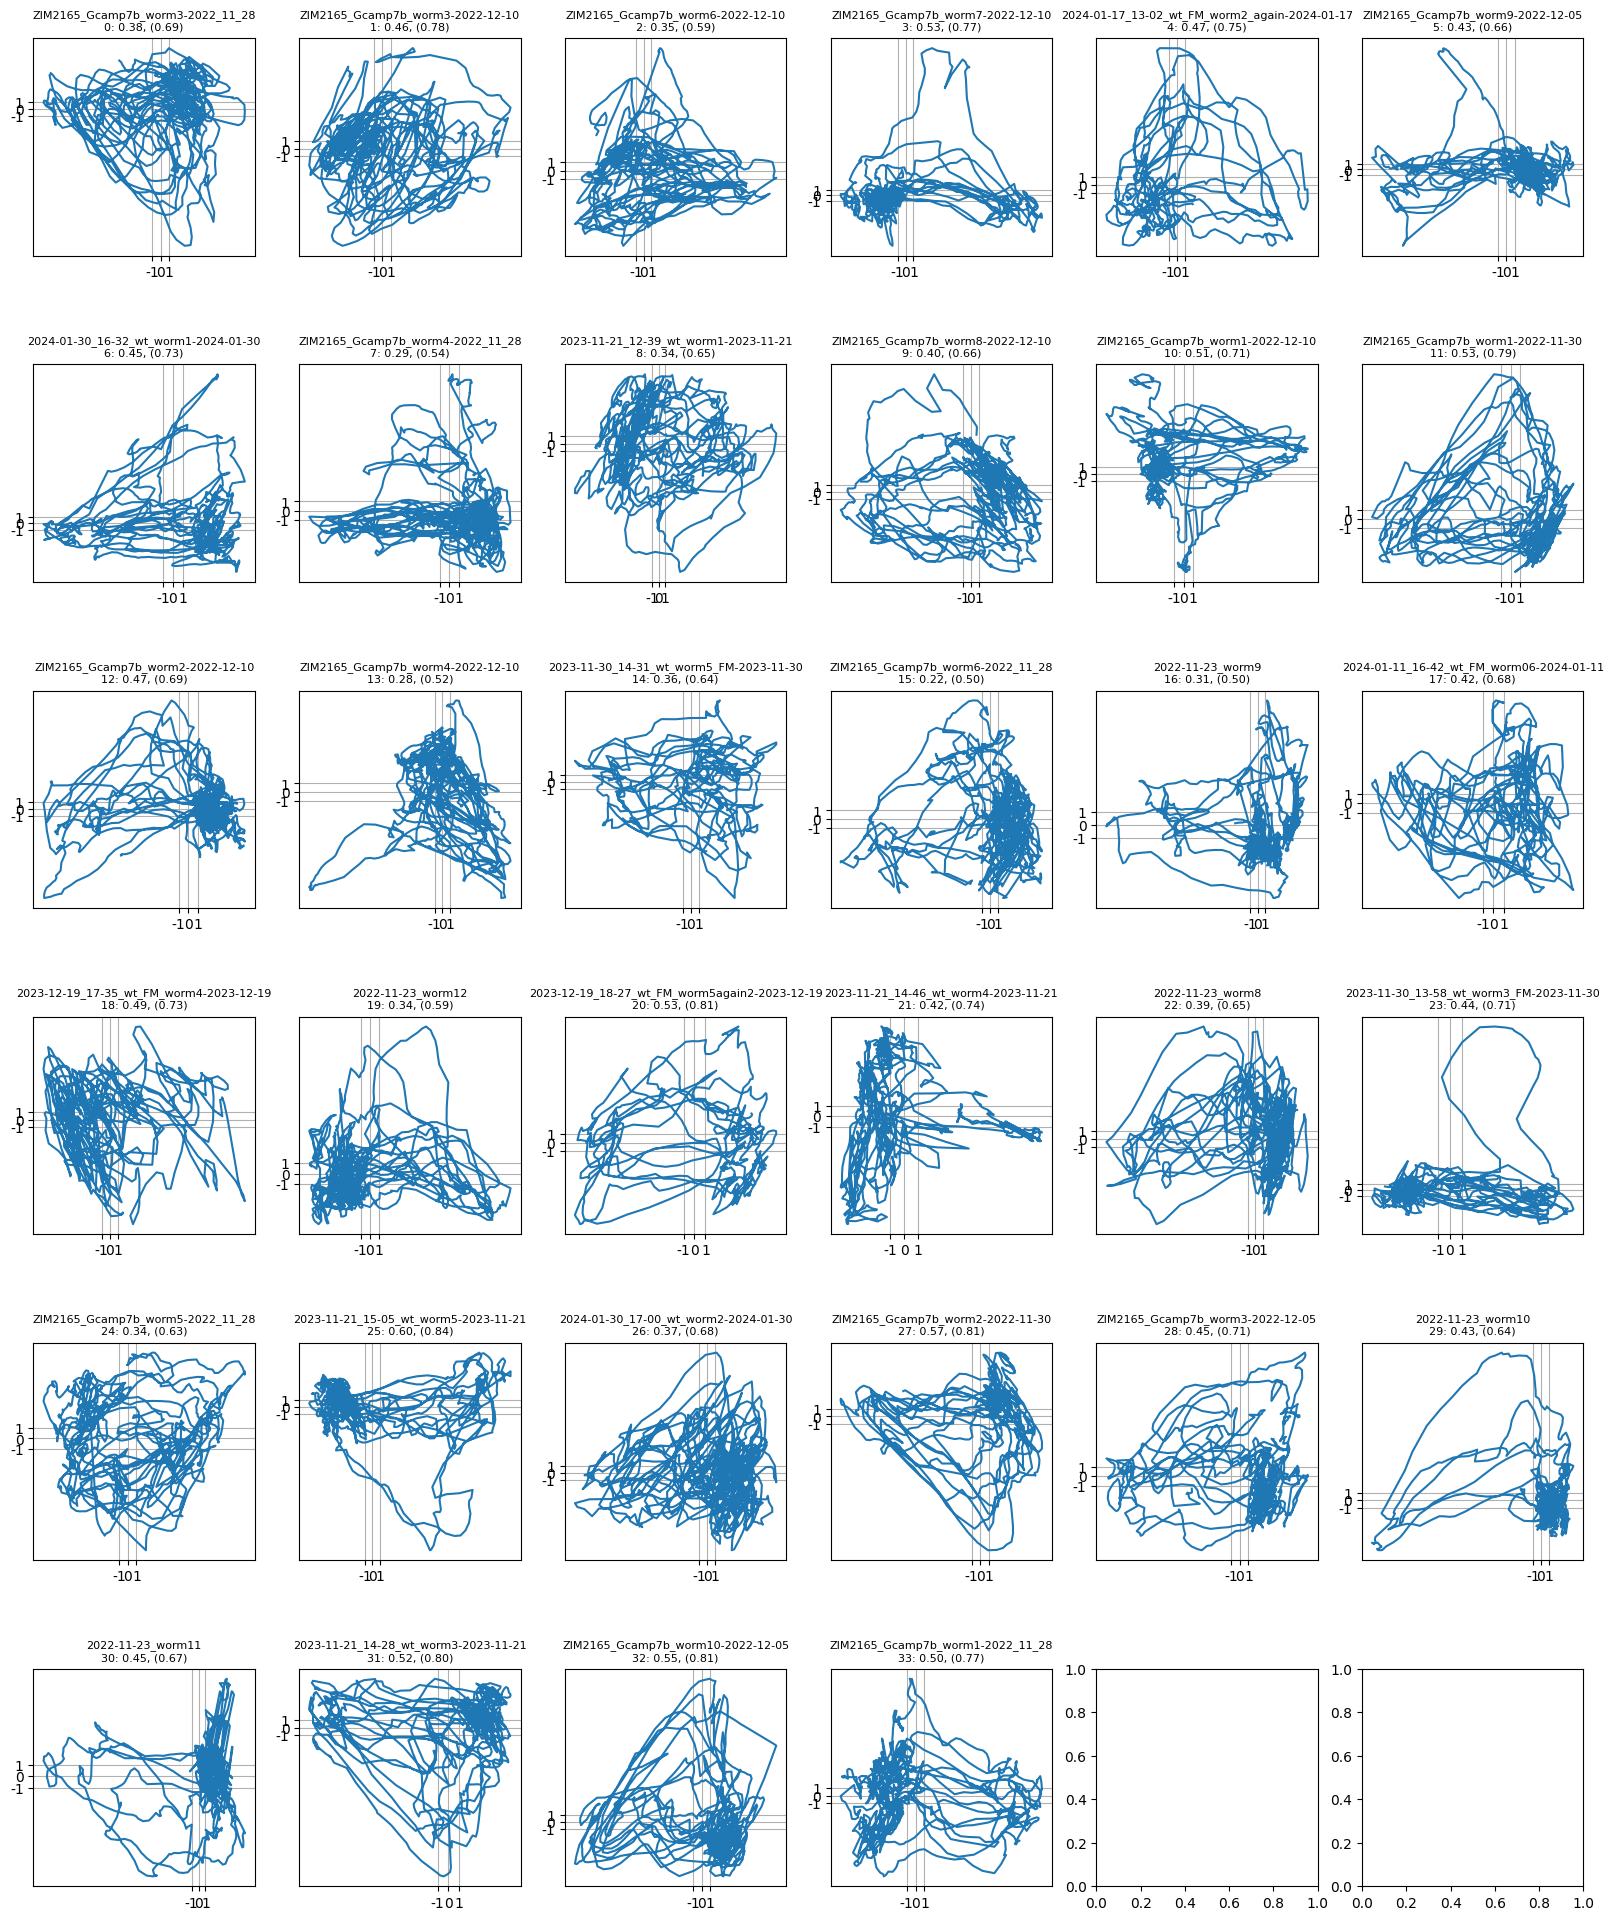

In [6]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

modes_manifold, traces_manifold, cca_loadings_man, vars_expl_man, vars_expl_man_rs = train_utils.get_manifolds(traces,
																											   [ds[selection] for ds in discrete_states],
																											   n_cc=2, n_pc=5)

plot_utils.plot_manifolds(filenames, modes_manifold, vars_expl_man, vars_expl_man_rs)

In [7]:
traces_residual = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces, traces_manifold)]

### analytical linear regression

In [8]:
reg_models_scores = list()
reg_models_losses = list()
reg_models_losses_tr = list()
for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]} ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

	score_per_split, loss_per_split, loss_tr_per_split = fit_analytical_model(splits, eigenworms[i].values, traces_residual[i].values)

	reg_models_scores.append(score_per_split)
	reg_models_losses.append(loss_per_split)
	reg_models_losses_tr.append(loss_tr_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data 2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data 3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data 4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data 5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data 6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data 7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data 8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data 9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data 10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data 11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data 12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data 13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data 14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data 15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data 16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data 17/34: 2022-11-23_worm9_no_image_data 18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 19/34: 2023-12-19

### GLM

In [9]:
glm_models_scores = list()
glm_models_losses = list()
glm_models_losses_tr = list()
# glm_models_params = list()

for i in range(len(filenames)):
	print(f'{i + 1}/{len(filenames)}: {filenames[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split = train_numerical_model(glm, splits,
																						   jnp.array(eigenworms[i].values),
																						   jnp.array(traces_residual[i].values))

	glm_models_scores.append(neuron_scores_per_split)
	glm_models_losses.append(losses_per_split)
	glm_models_losses_tr.append(losses_tr_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

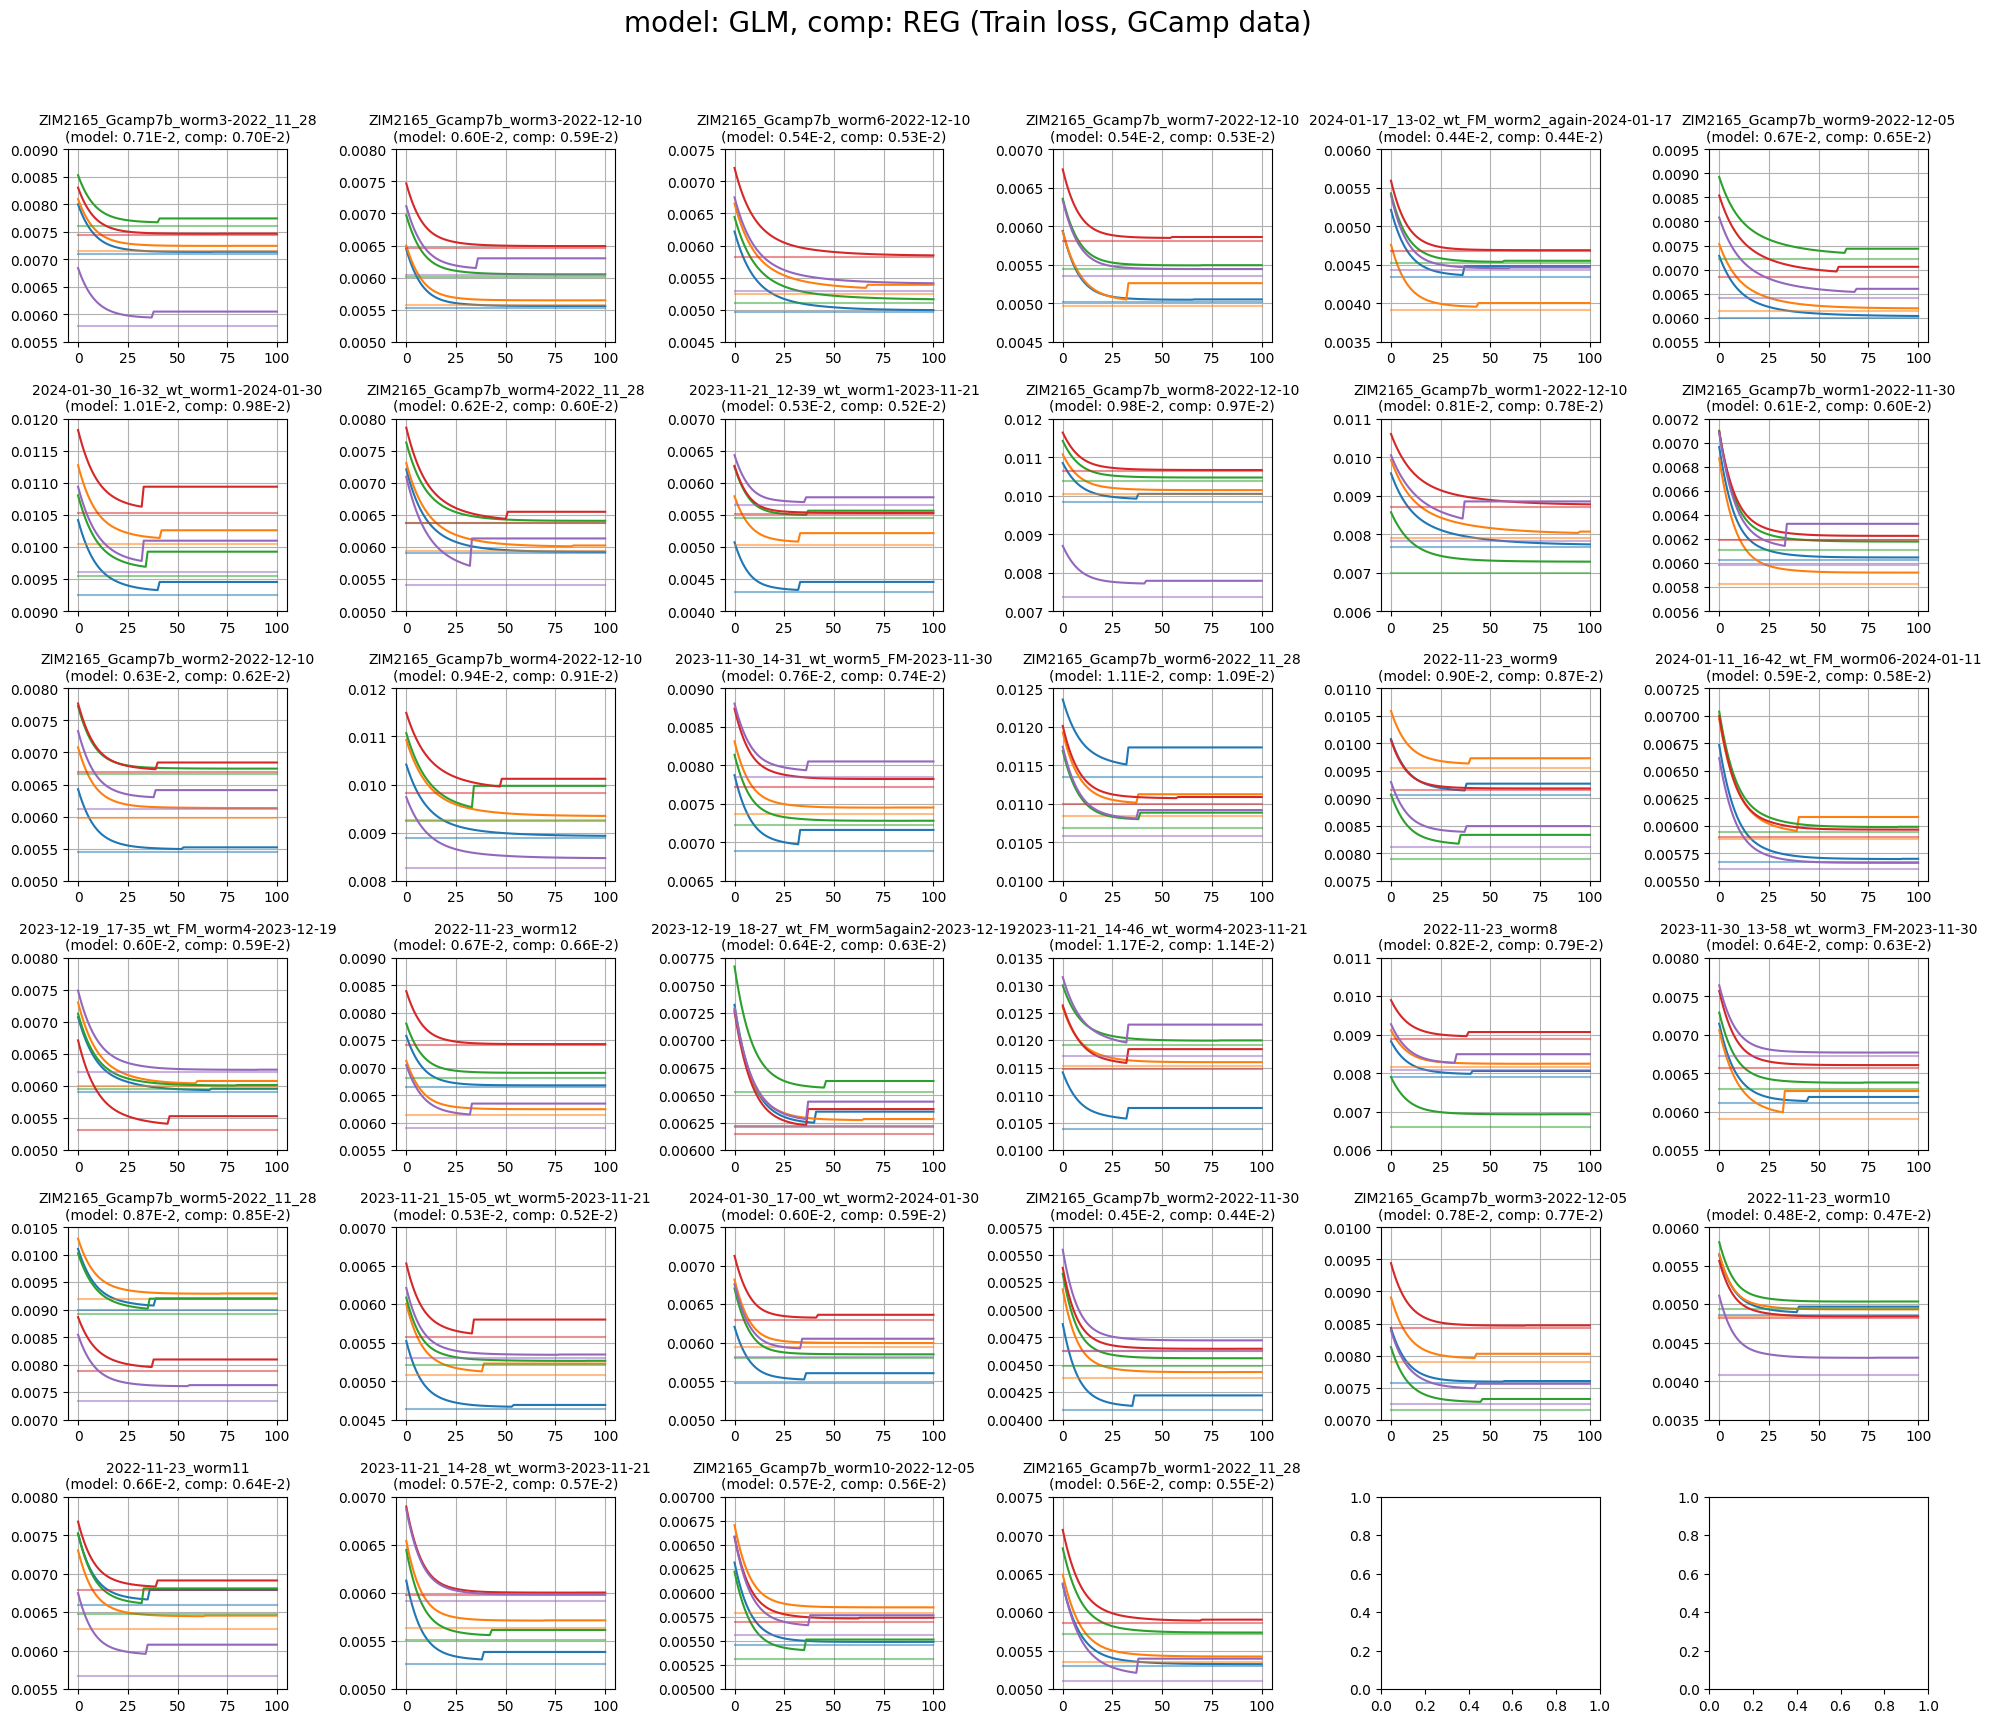

In [10]:
plot_utils.plot_losses(filenames, glm_models_losses_tr, [loss[:, None] * np.ones((1, glm_models_losses_tr[0].shape[1])) for loss in reg_models_losses_tr], 'model: GLM, comp: REG (Train loss, GCamp data)')

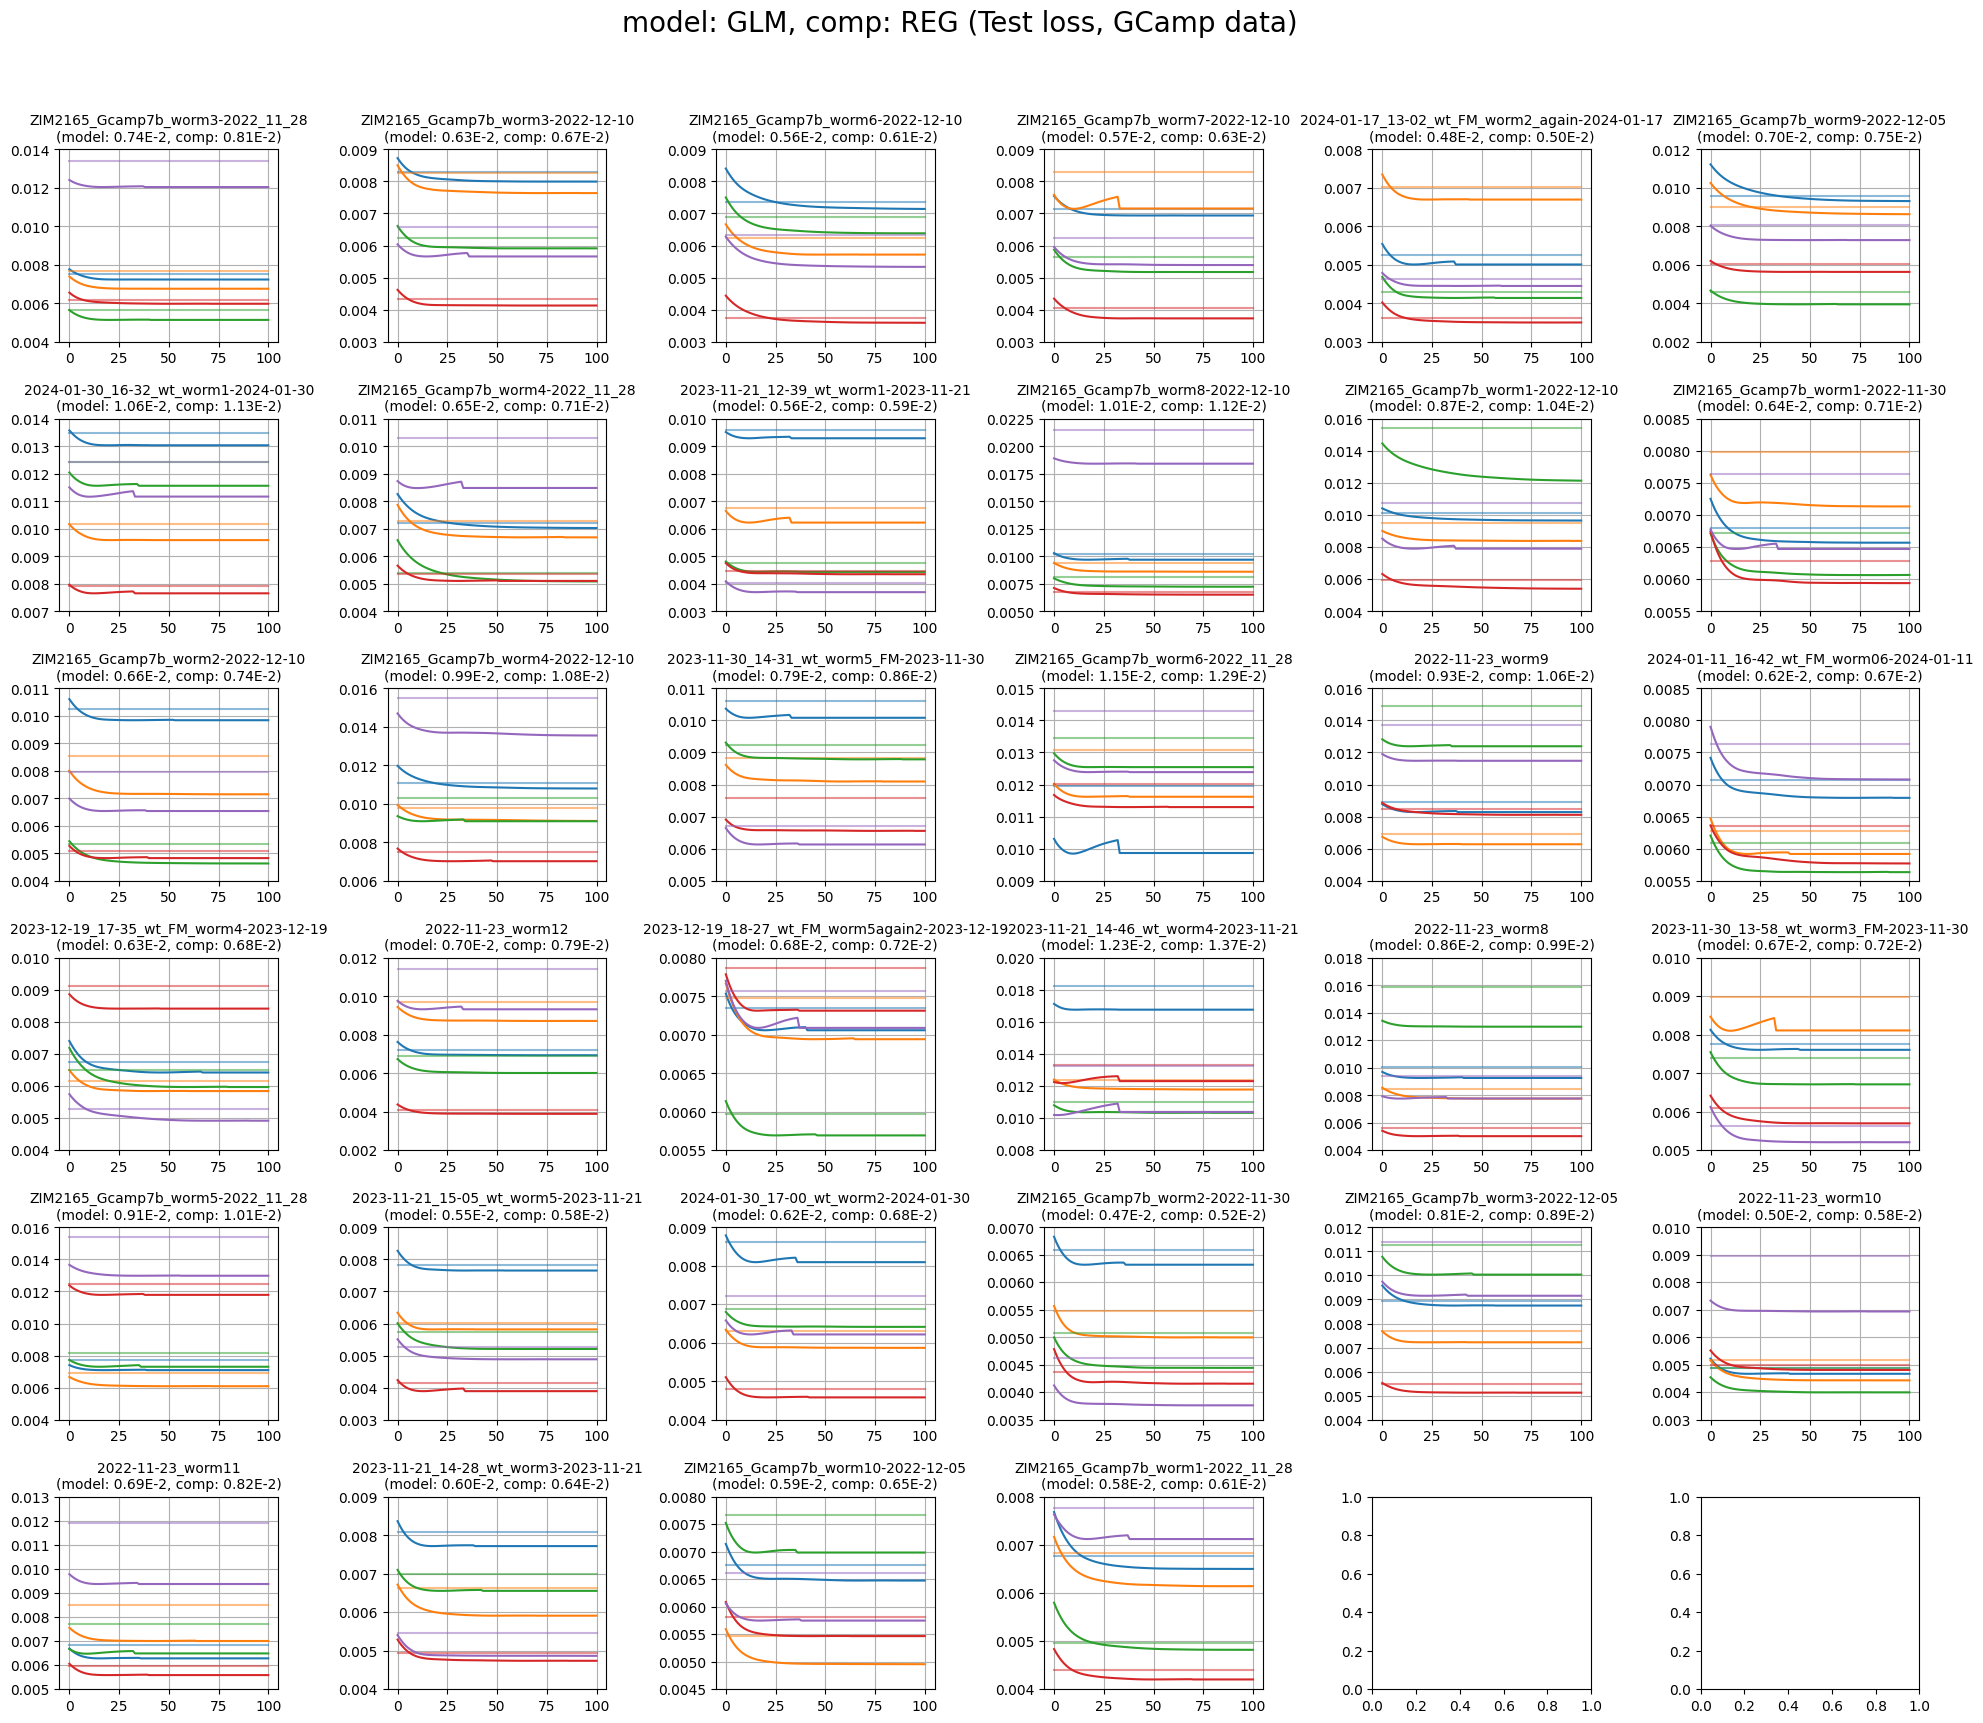

In [11]:
plot_utils.plot_losses(filenames, glm_models_losses, [loss[:, None] * np.ones((1, glm_models_losses[0].shape[1])) for loss in reg_models_losses], 'model: GLM, comp: REG (Test loss, GCamp data)')

### HGM

In [12]:
hgm_models_scores = list()
hgm_models_losses = list()
hgm_models_losses_tr = list()
# hgm_models_params = list()

for i in range(len(filenames)):
	print(f'{i + 1}/{len(filenames)}: {filenames[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split = train_numerical_model(hgm, splits,
																						   jnp.array(eigenworms[i].values),
																						   jnp.array(traces_residual[i].values),
																						   jnp.array(modes_manifold[i].values))

	hgm_models_scores.append(neuron_scores_per_split)
	hgm_models_losses.append(losses_per_split)
	hgm_models_losses_tr.append(losses_tr_per_split)

1/34: ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data  2/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data  4/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  5/34: 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data  6/34: ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data  7/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  8/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  9/34: 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data  10/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  11/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  12/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  13/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  14/34: ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data  15/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  16/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  17/34: 2022-11-23_worm9_no_image_data  18/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 

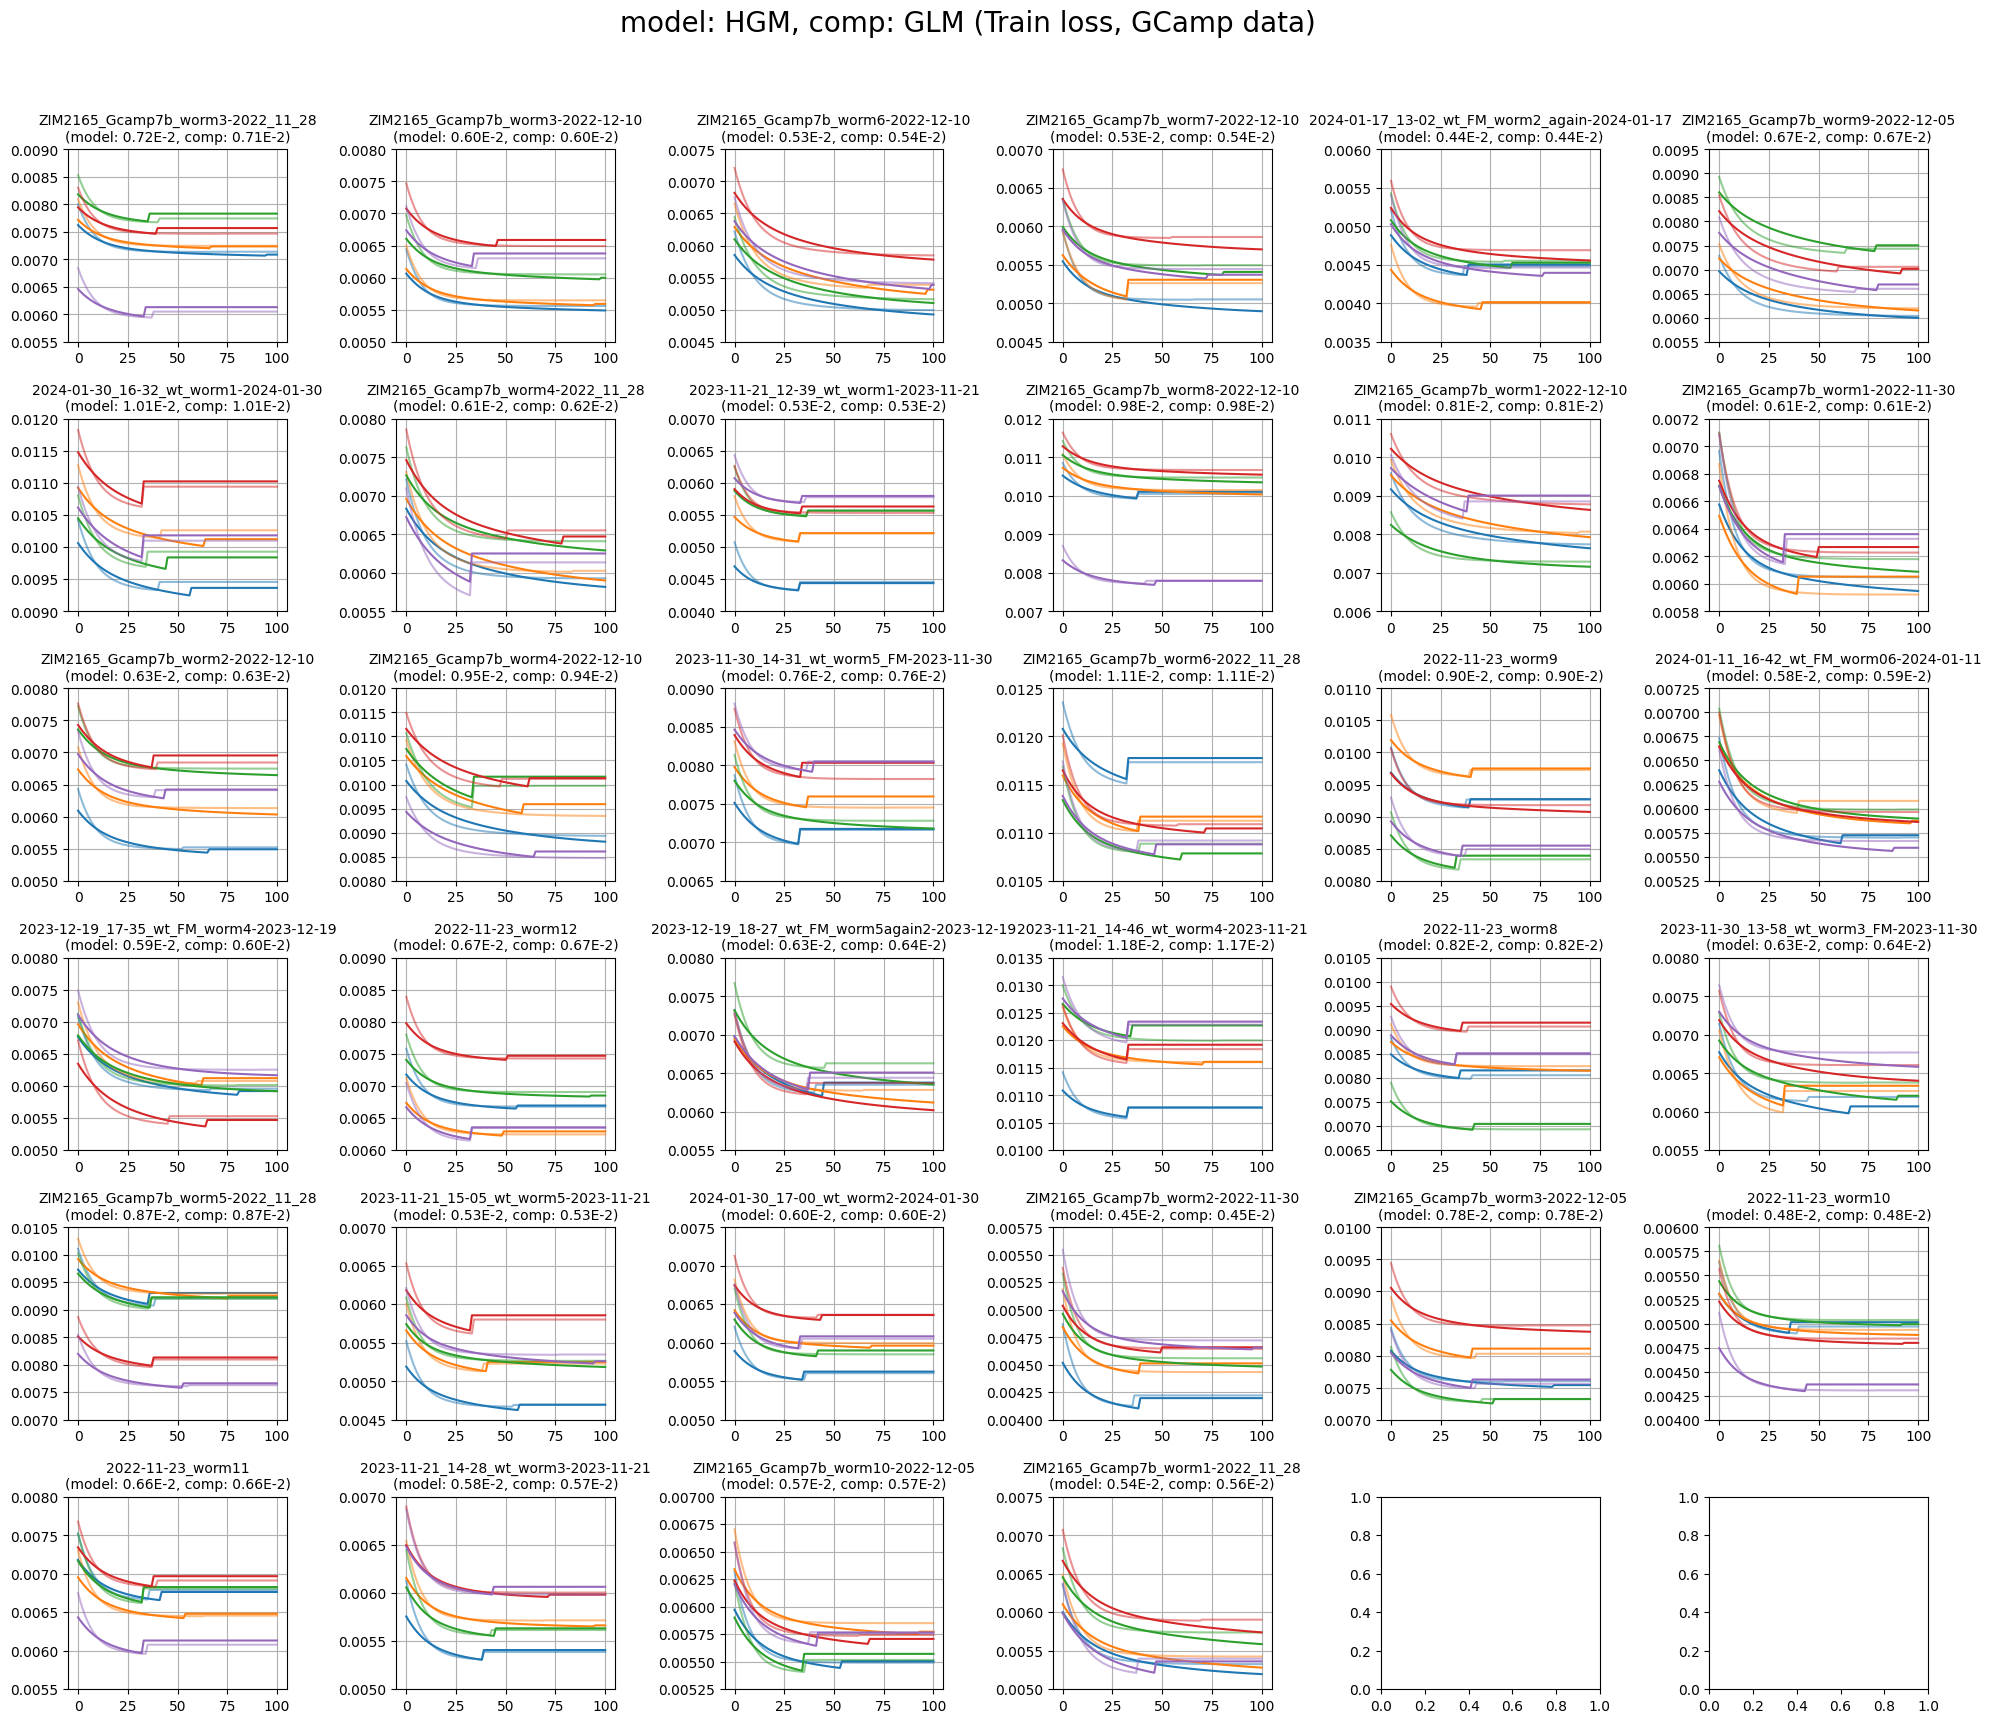

In [13]:
plot_utils.plot_losses(filenames, hgm_models_losses_tr, glm_models_losses_tr, 'model: HGM, comp: GLM (Train loss, GCamp data)')

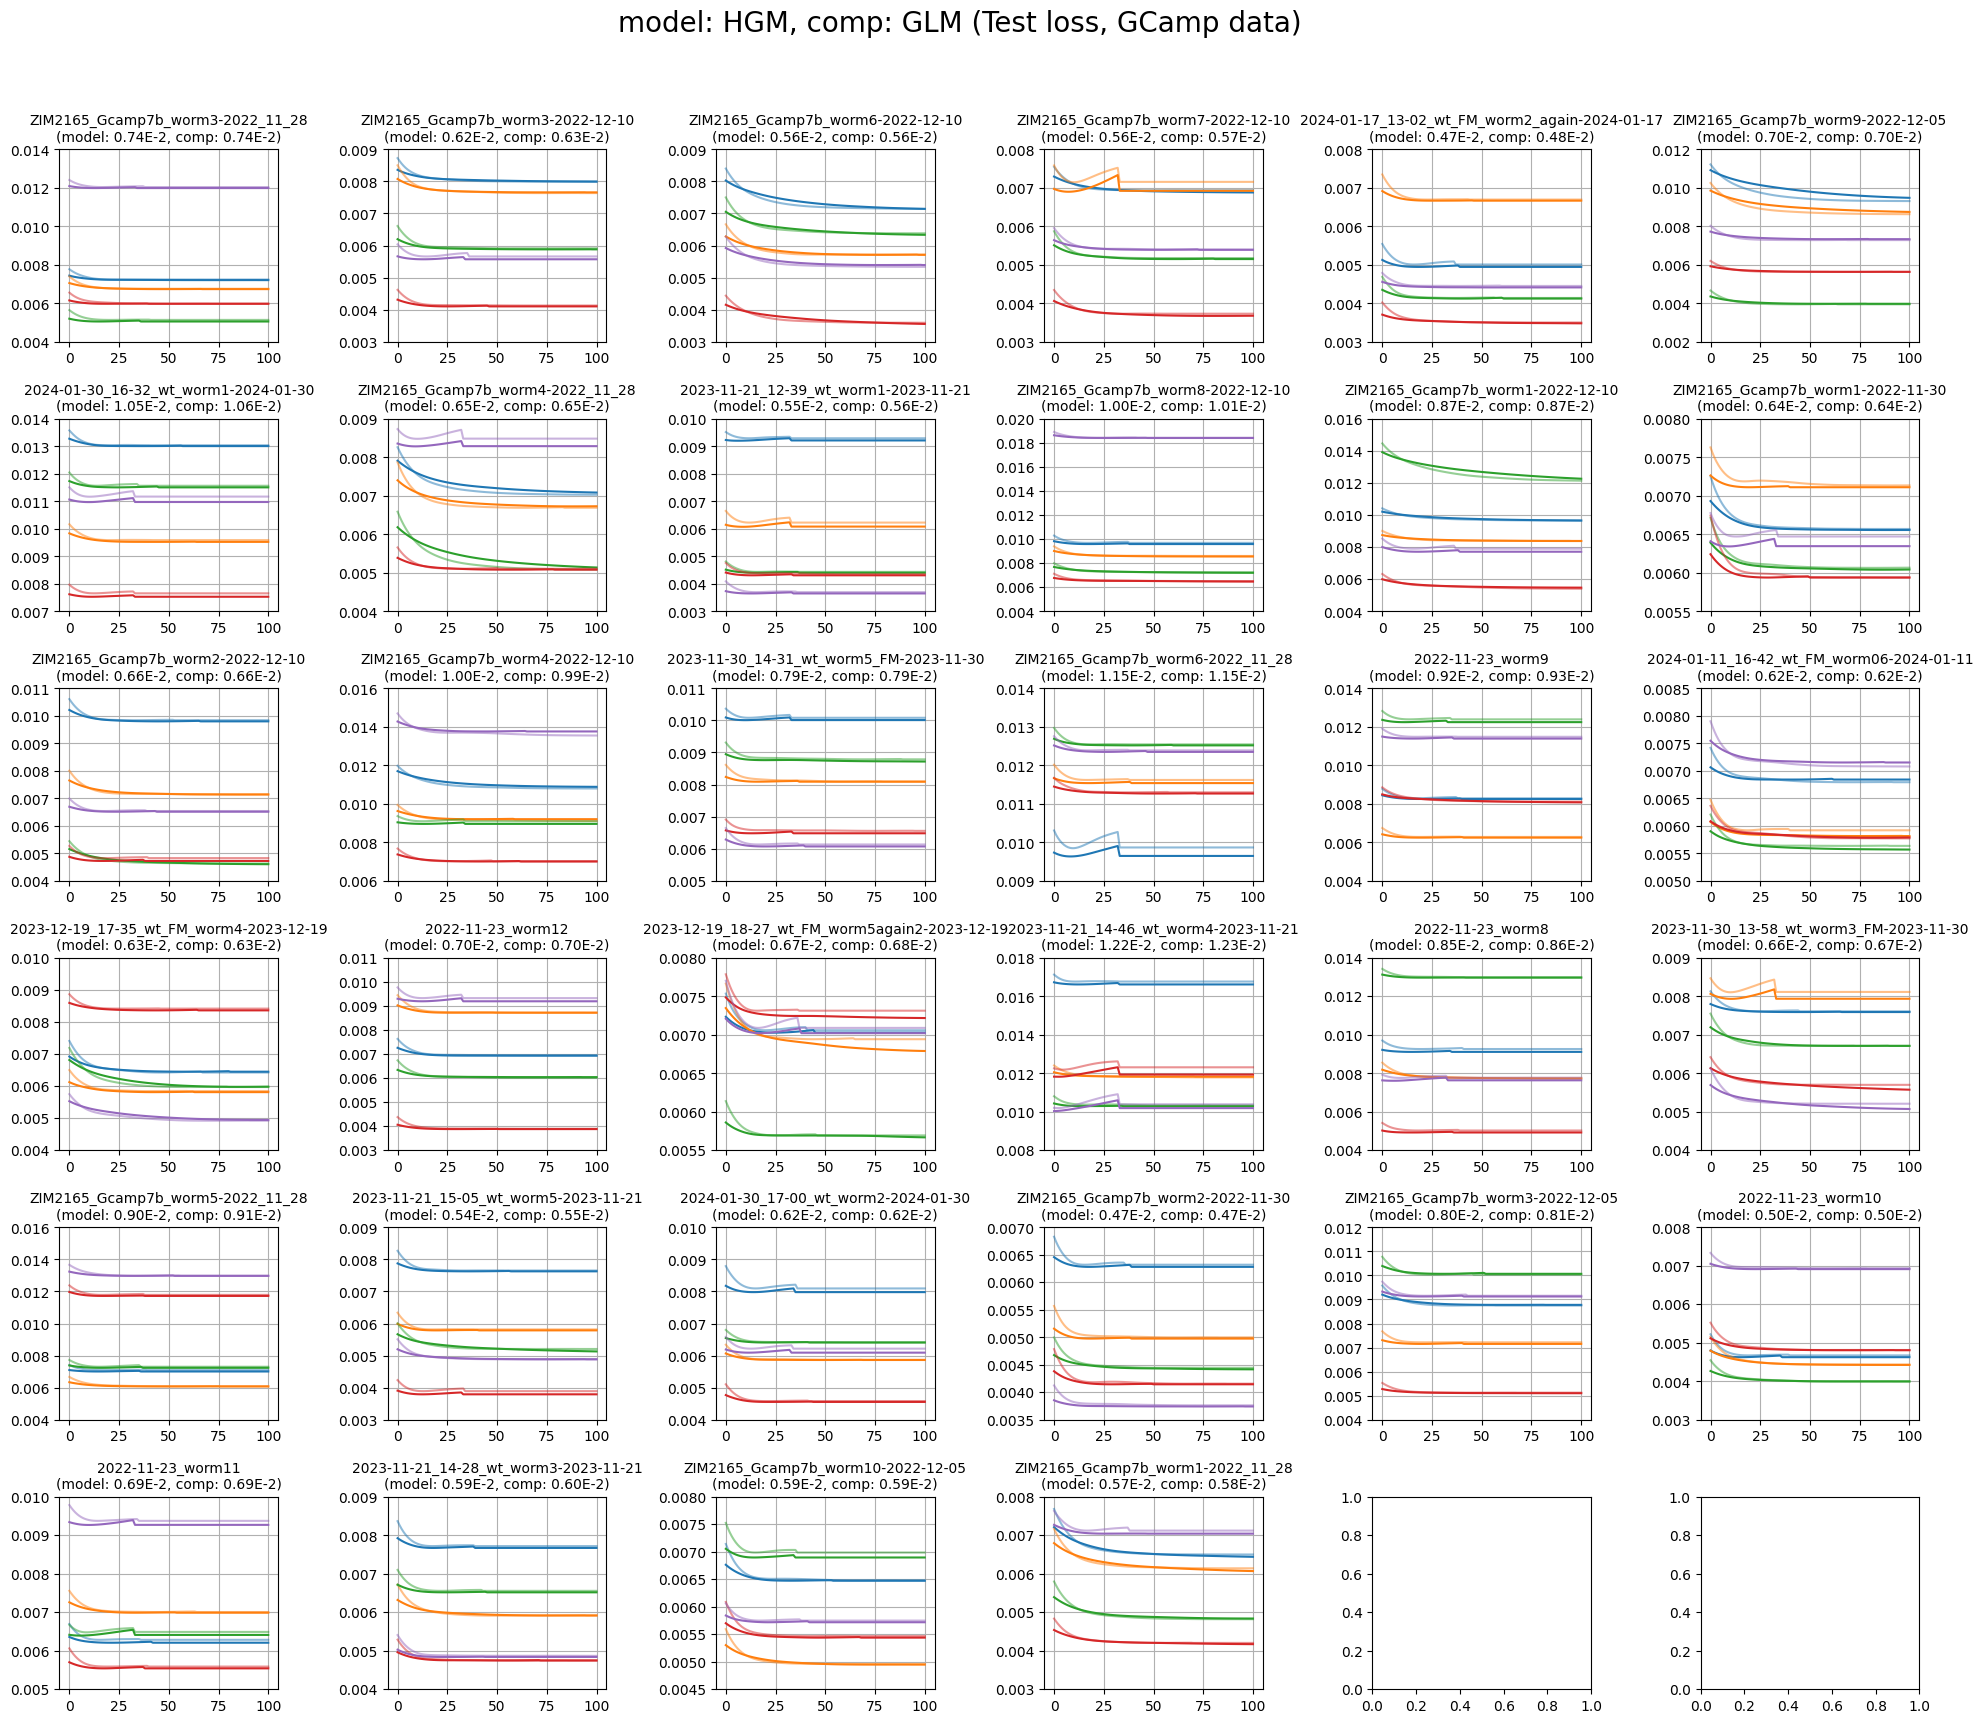

In [14]:
plot_utils.plot_losses(filenames, hgm_models_losses, glm_models_losses, 'model: HGM, comp: GLM (Test loss, GCamp data)')

# GFP DATA

In [15]:
path_gfp = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_gfp/'
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

In [16]:
for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

### manifold

0.23103673113535972 0.4576620918340124


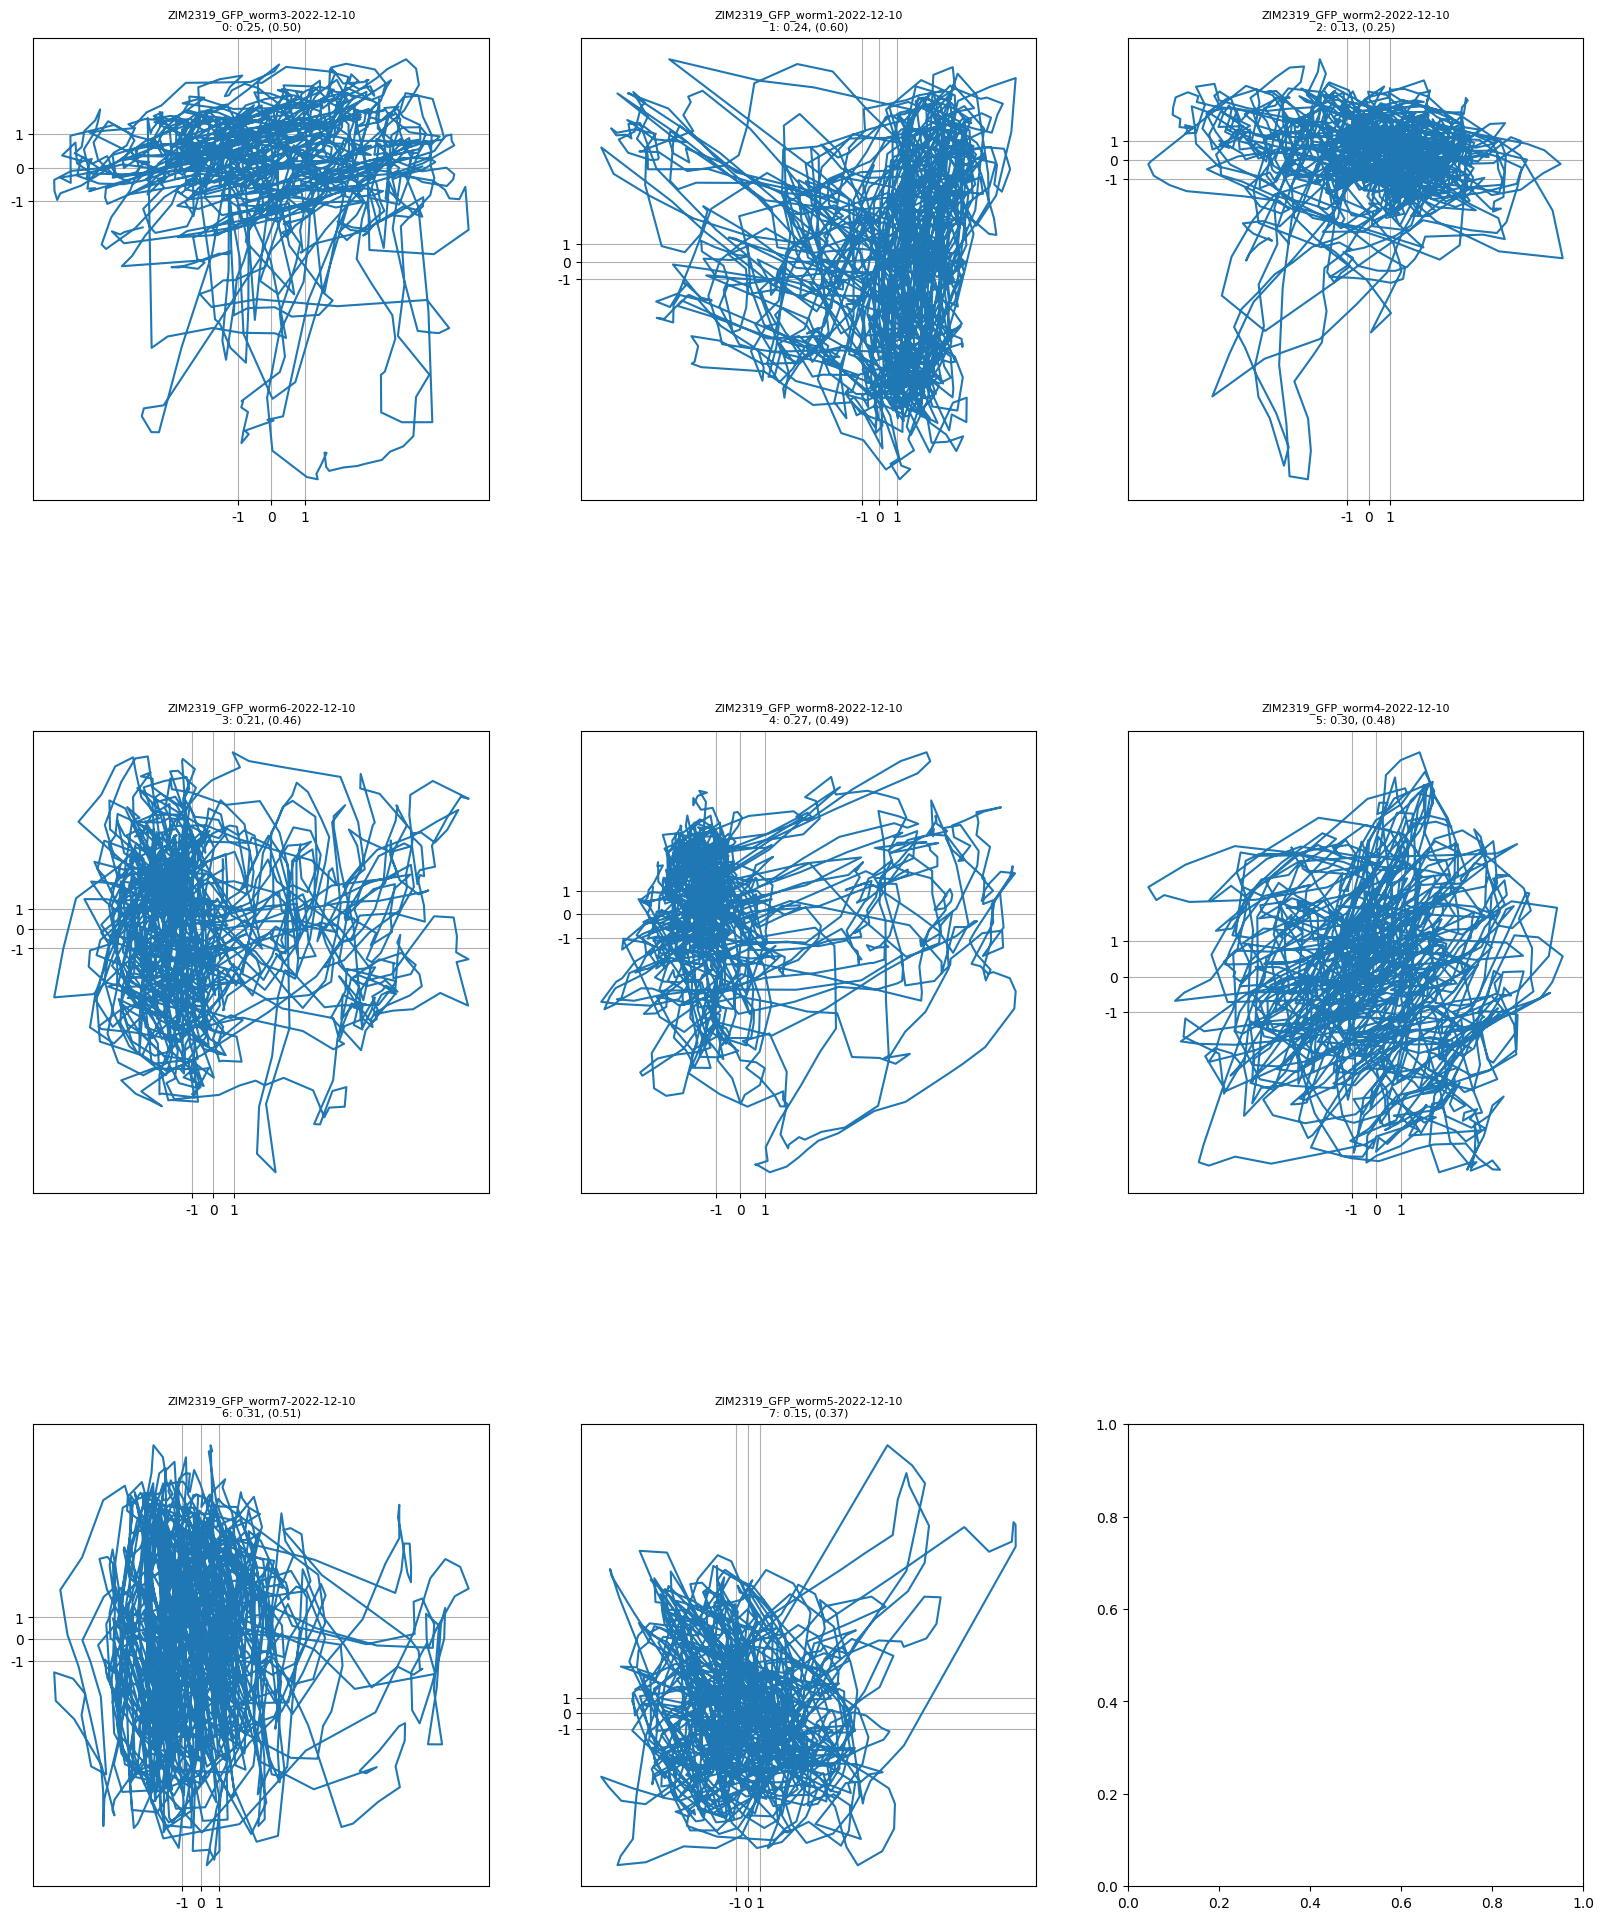

In [17]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

(modes_manifold_gfp,
 traces_manifold_gfp,
 cca_loadings_man_gfp,
 vars_expl_man_gfp,
 vars_expl_man_rs_gfp) = train_utils.get_manifolds(traces_gfp,
												   [ds[selection] for ds in discrete_states_gfp],
												   n_cc=2, n_pc=5)

plot_utils.plot_manifolds(filenames_gfp, modes_manifold_gfp, vars_expl_man_gfp, vars_expl_man_rs_gfp)

In [18]:
traces_residual_gfp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gfp, traces_manifold_gfp)]

### analytical linear regression

In [19]:
reg_models_scores_gfp = list()
reg_models_losses_gfp = list()
reg_models_losses_tr_gfp = list()
for i in range(len(filenames_gfp)):
	print(f'{i+1}/{len(filenames_gfp)}: {filenames_gfp[i]} ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_gfp[i].values.shape[0]), discrete_states_gfp[i]['REV'].values))

	score_per_split, loss_per_split, loss_tr_per_split = fit_analytical_model(splits, eigenworms_gfp[i].values, traces_residual_gfp[i].values)

	reg_models_scores_gfp.append(score_per_split)
	reg_models_losses_gfp.append(loss_per_split)
	reg_models_losses_tr_gfp.append(loss_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data 2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data 3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data 4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data 5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data 6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data 7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data 8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data 

### GLM

In [20]:
glm_models_scores_gfp = list()
glm_models_losses_gfp = list()
glm_models_losses_tr_gfp = list()
# glm_models_params_gfp = list()

for i in range(len(filenames_gfp)):
	print(f'{i + 1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_gfp[i].values.shape[0]), discrete_states_gfp[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split = train_numerical_model(glm, splits,
																						   jnp.array(eigenworms_gfp[i].values),
																						   jnp.array(traces_residual_gfp[i].values))

	glm_models_scores_gfp.append(neuron_scores_per_split)
	glm_models_losses_gfp.append(losses_per_split)
	glm_models_losses_tr_gfp.append(losses_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

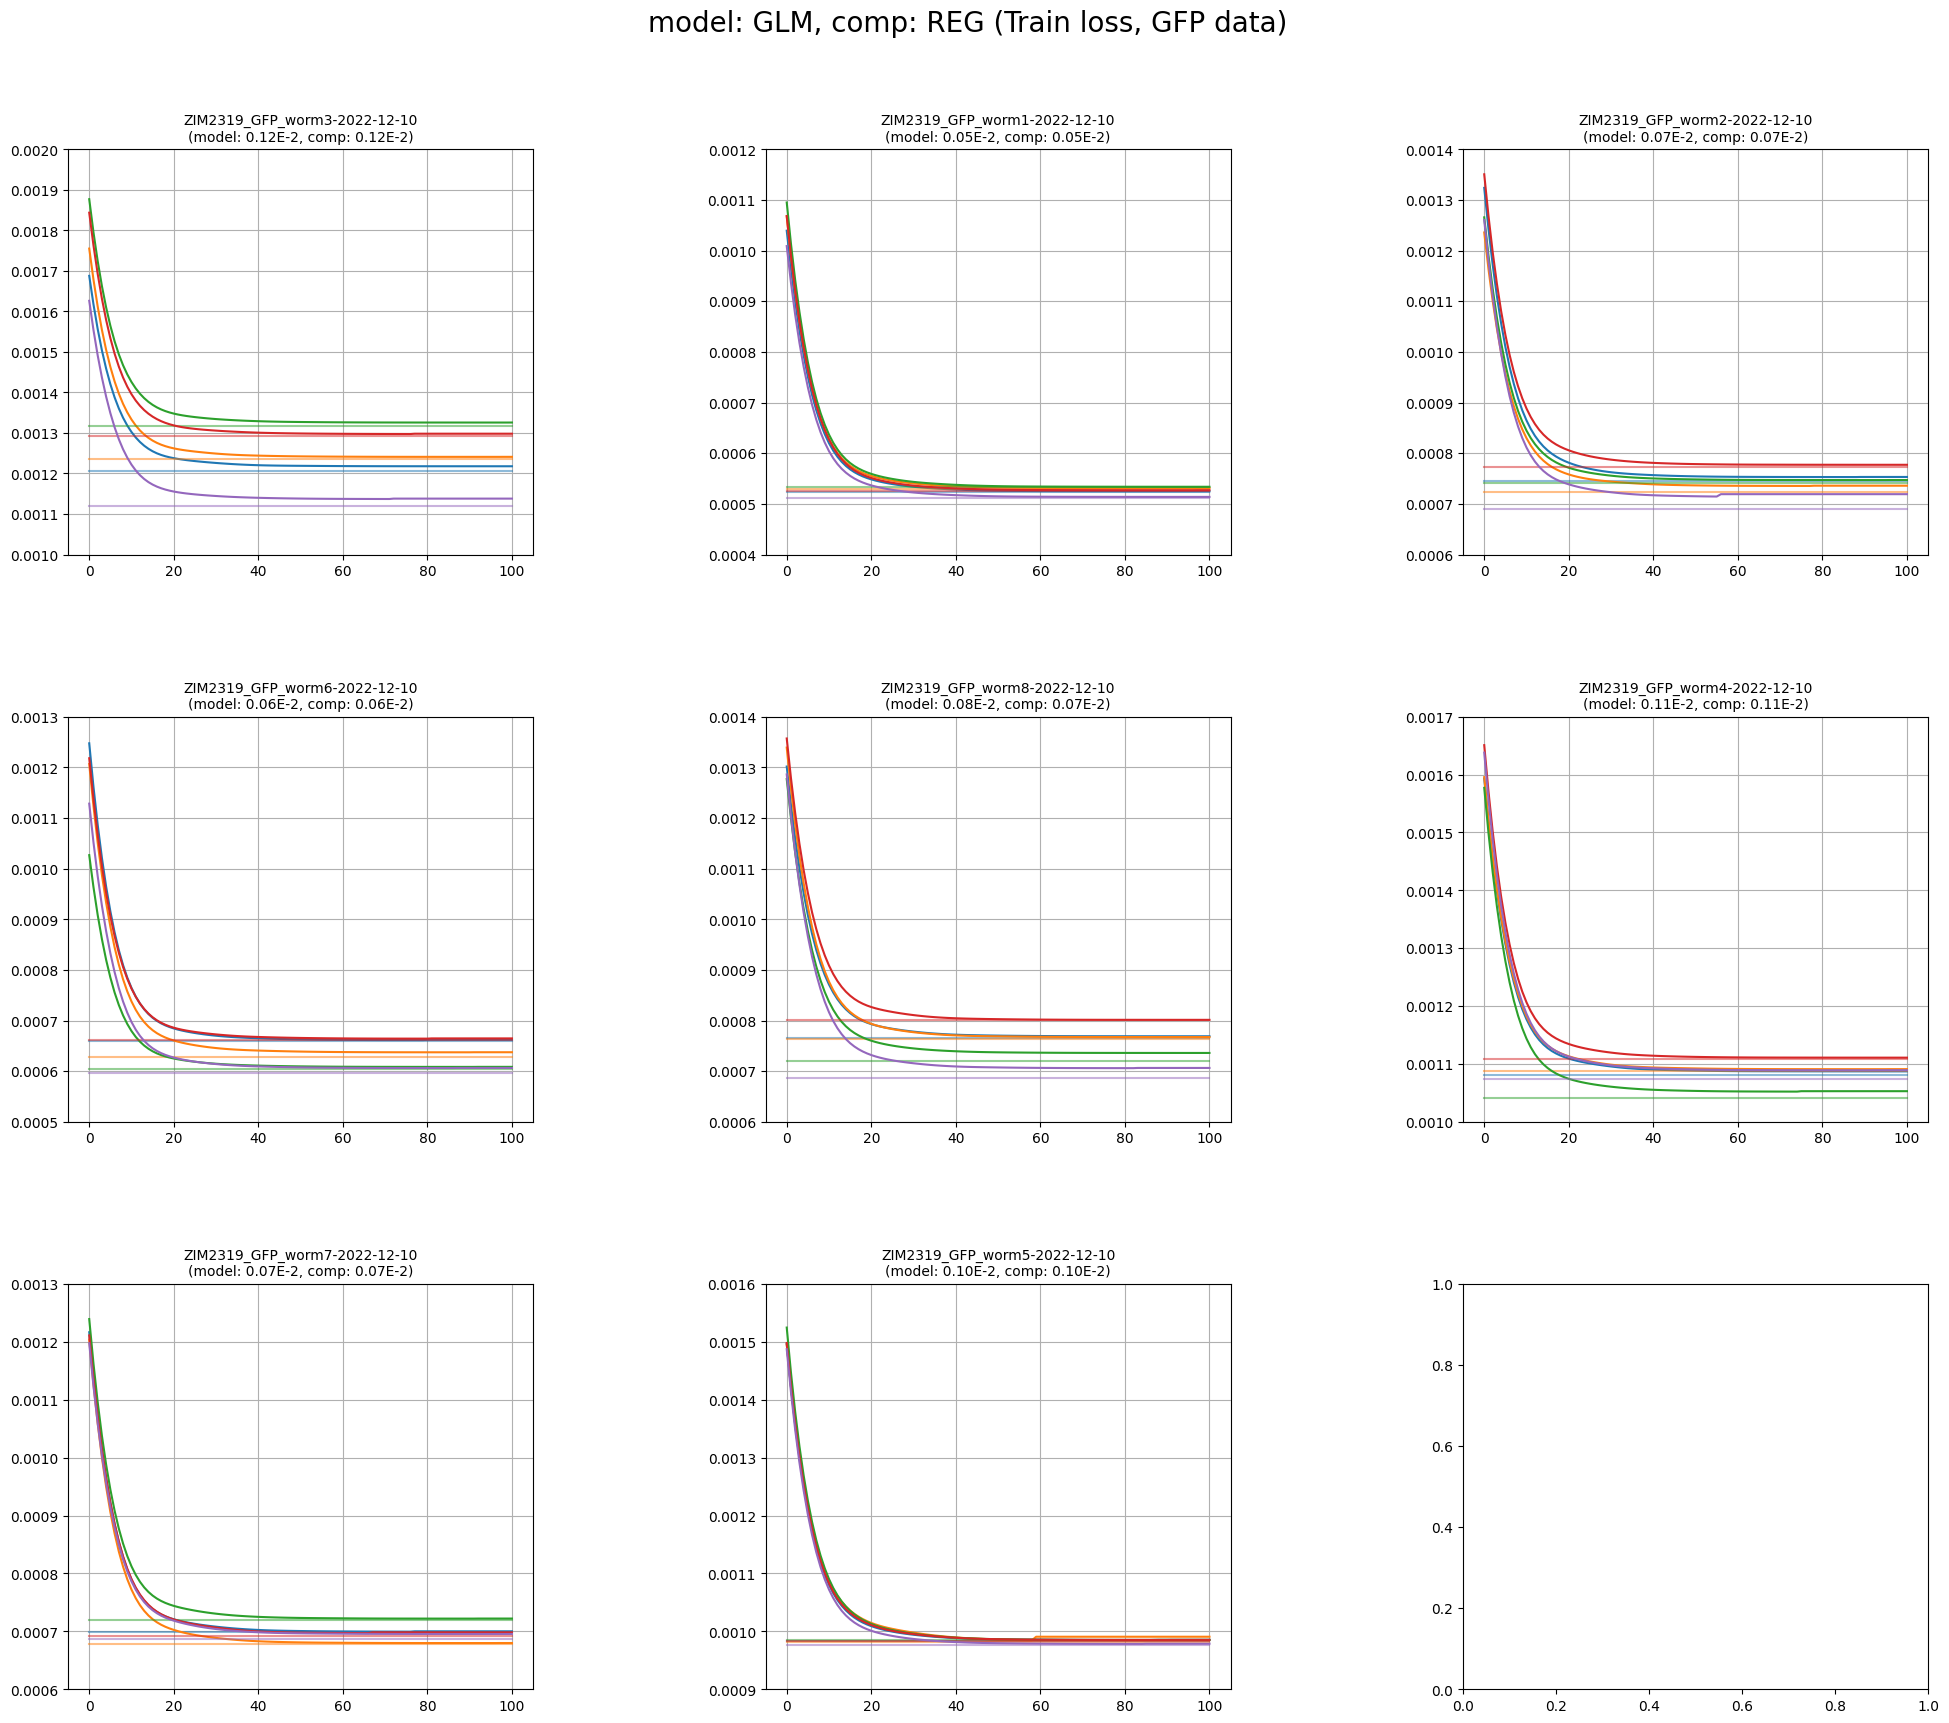

In [21]:
plot_utils.plot_losses(filenames_gfp, glm_models_losses_tr_gfp, [loss[:, None] * np.ones((1, glm_models_losses_tr_gfp[0].shape[1])) for loss in reg_models_losses_tr_gfp], 'model: GLM, comp: REG (Train loss, GFP data)')

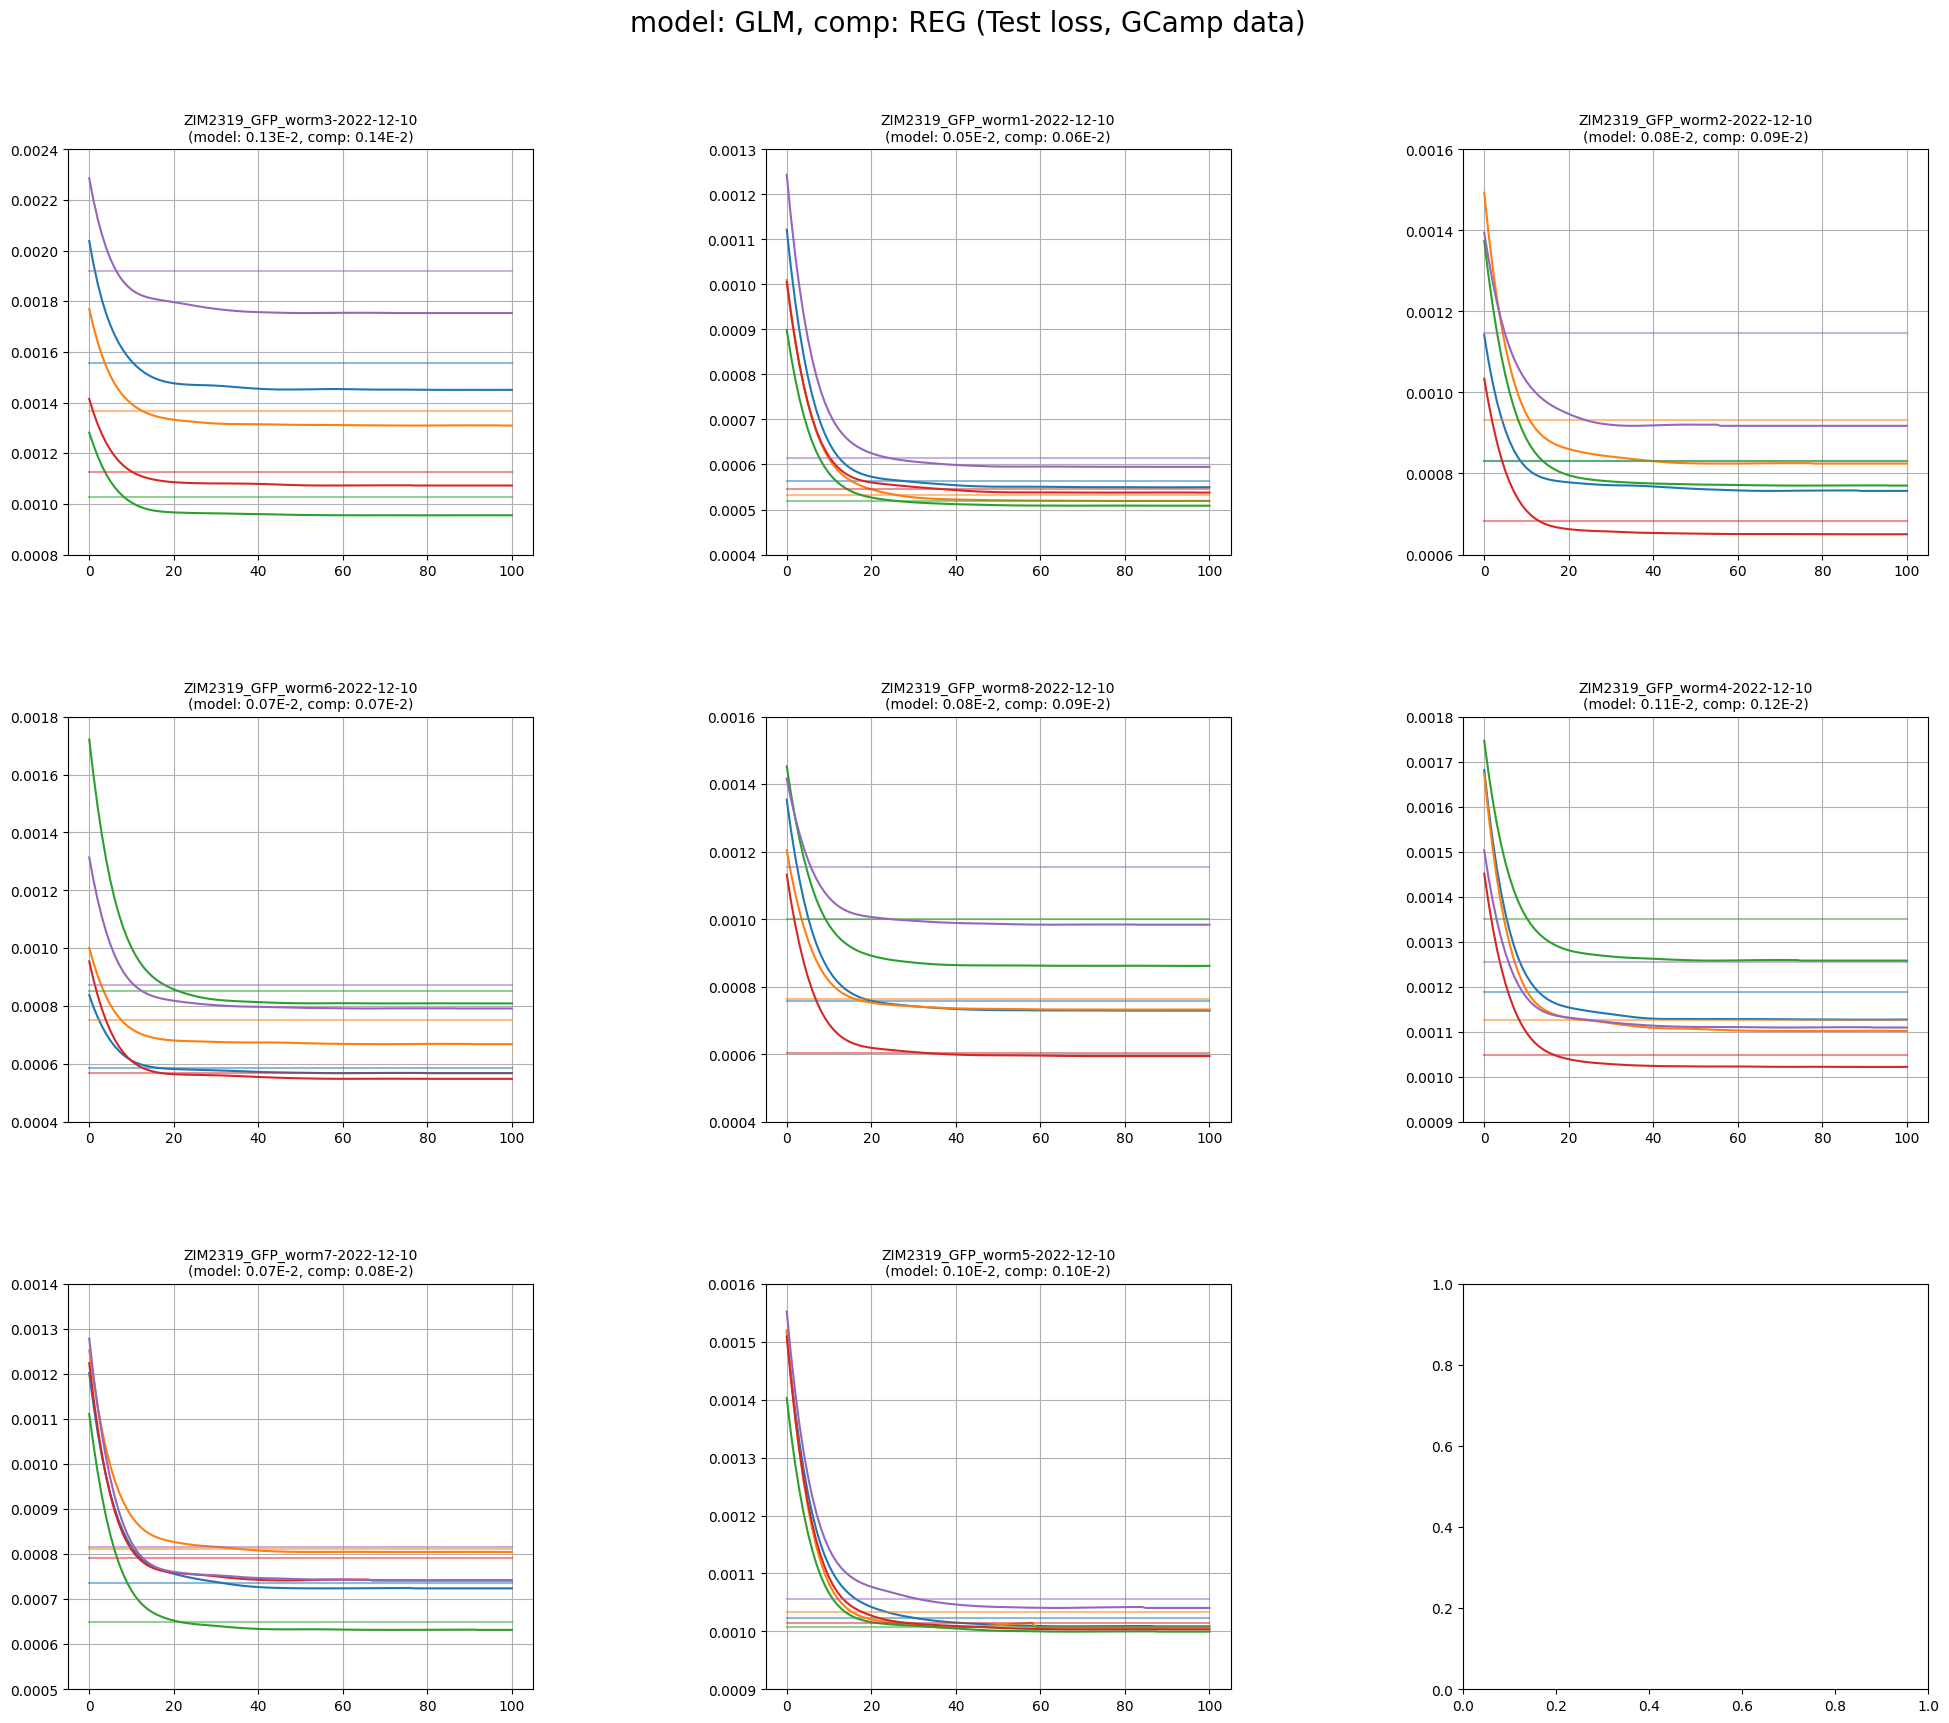

In [22]:
plot_utils.plot_losses(filenames_gfp, glm_models_losses_gfp, [loss[:, None] * np.ones((1, glm_models_losses_gfp[0].shape[1])) for loss in reg_models_losses_gfp], 'model: GLM, comp: REG (Test loss, GCamp data)')

### HGM

In [23]:
hgm_models_scores_gfp = list()
hgm_models_losses_gfp = list()
hgm_models_losses_tr_gfp = list()
# hgm_models_params_gfp = list()

for i in range(len(filenames_gfp)):
	print(f'{i + 1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values))

	neuron_scores_per_split, losses_per_split, losses_tr_per_split = train_numerical_model(hgm, splits,
																						   jnp.array(eigenworms_gfp[i].values),
																						   jnp.array(traces_residual_gfp[i].values),
																						   jnp.array(modes_manifold_gfp[i].values))

	hgm_models_scores_gfp.append(neuron_scores_per_split)
	hgm_models_losses_gfp.append(losses_per_split)
	hgm_models_losses_tr_gfp.append(losses_tr_per_split)

1/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  

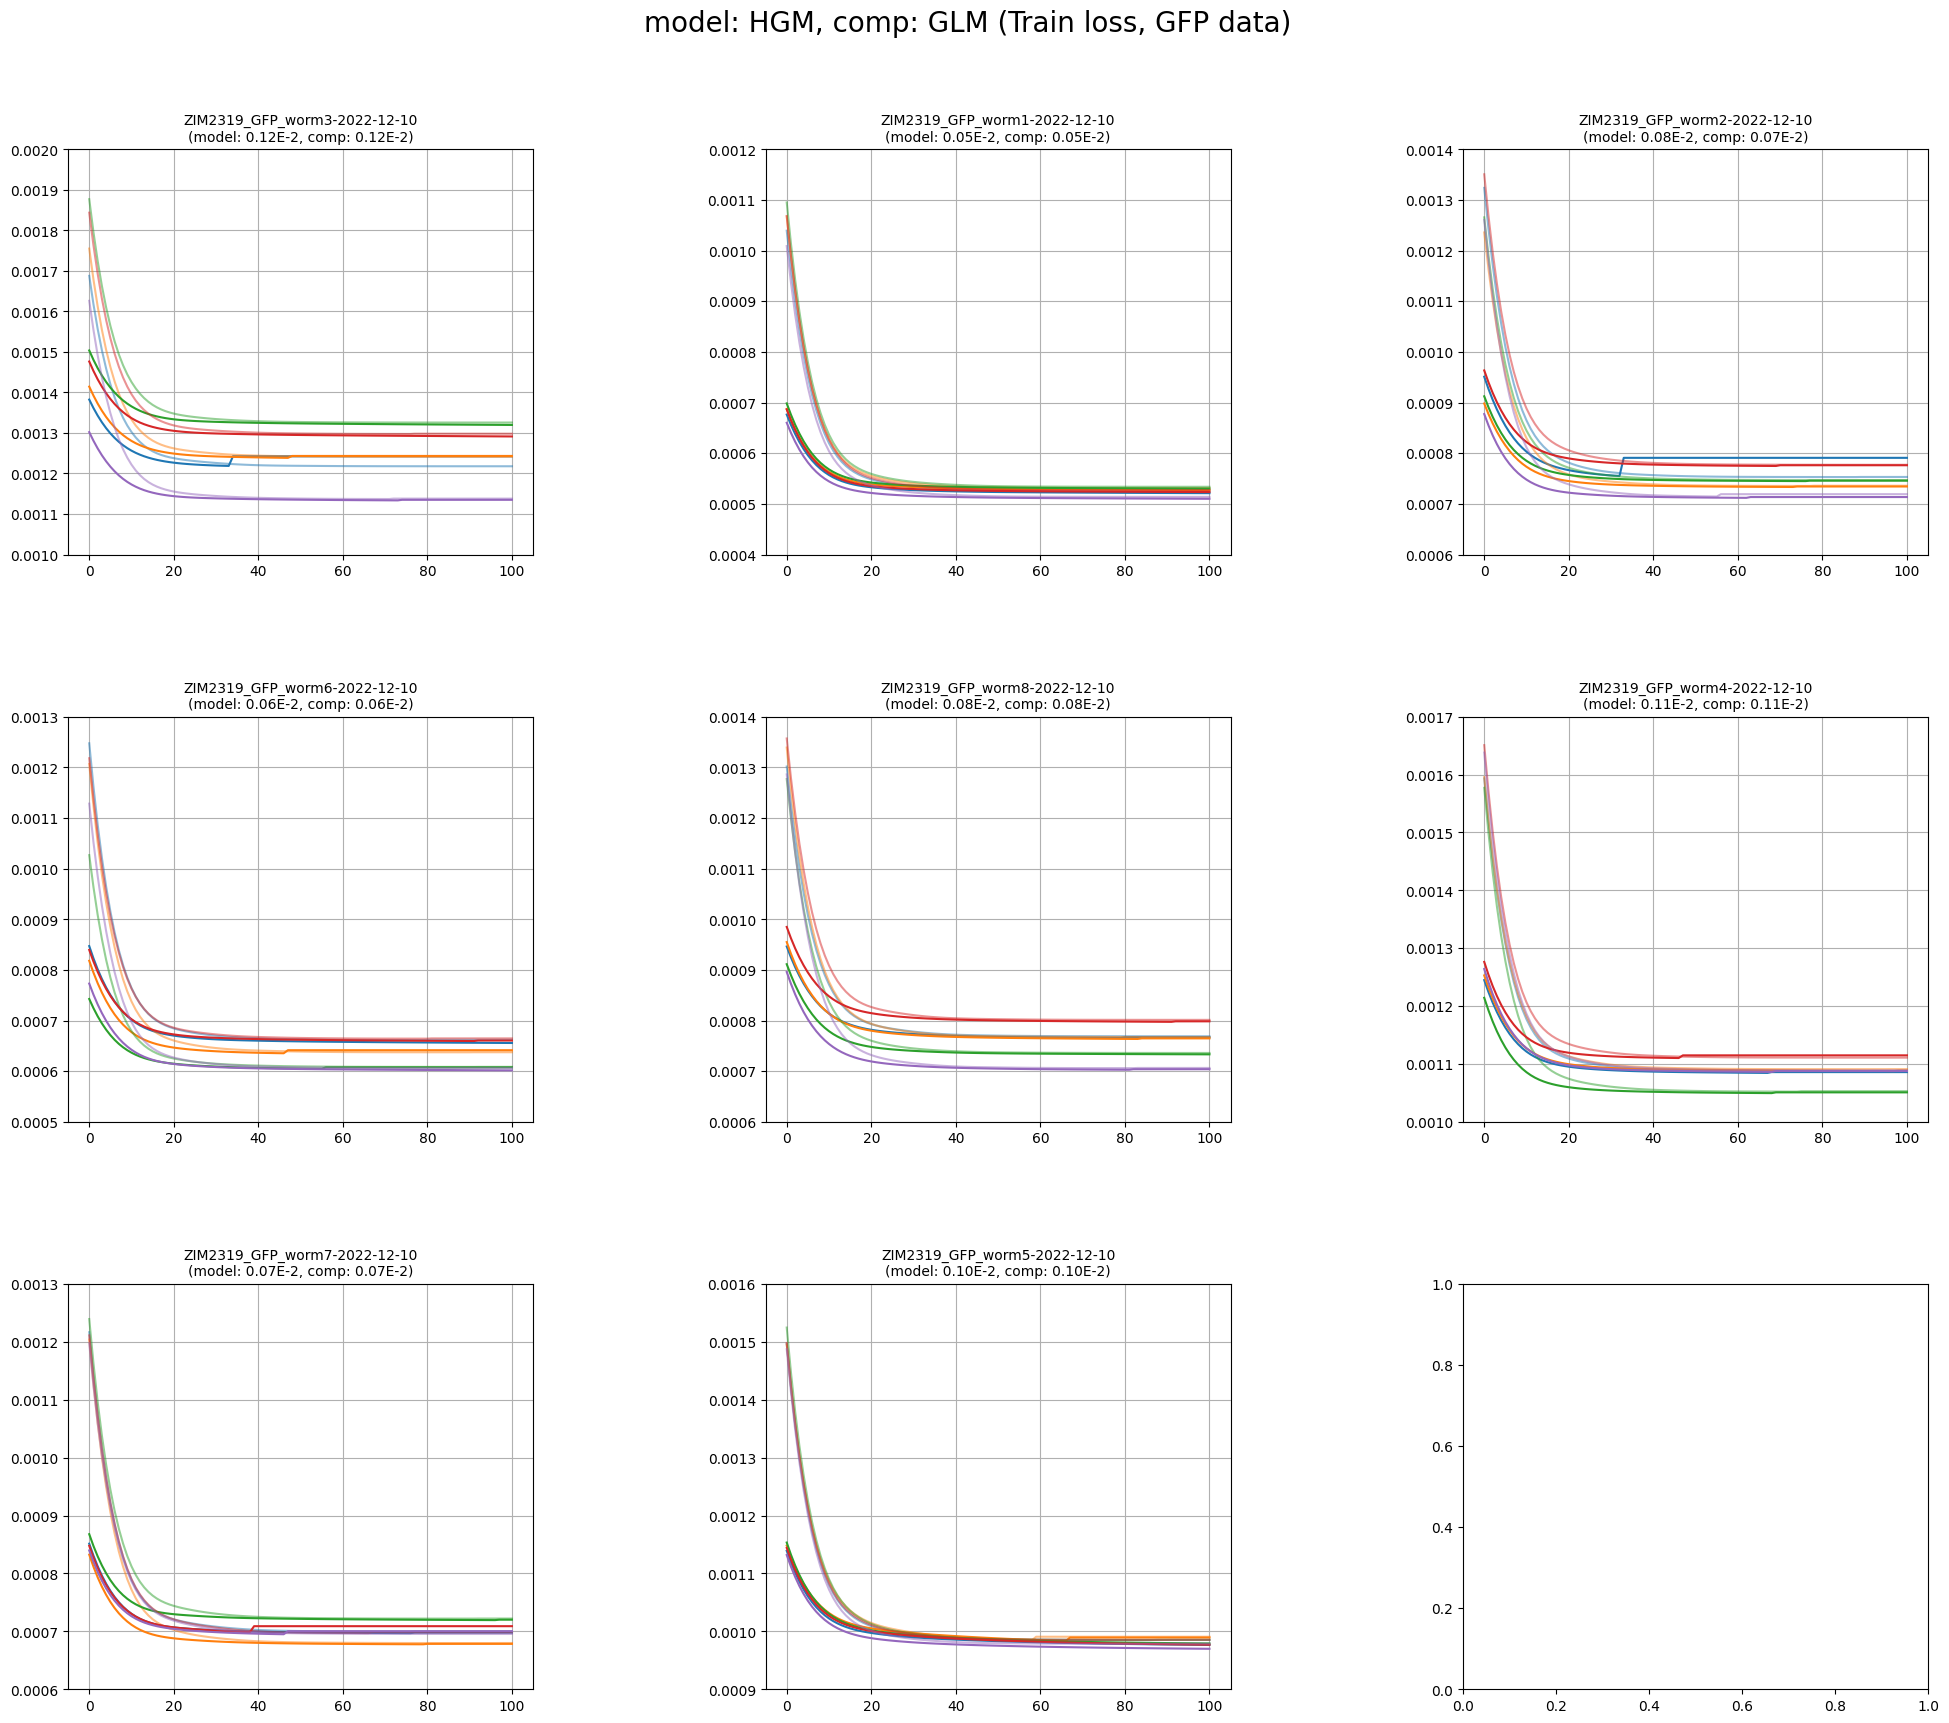

In [24]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_tr_gfp, glm_models_losses_tr_gfp, 'model: HGM, comp: GLM (Train loss, GFP data)')

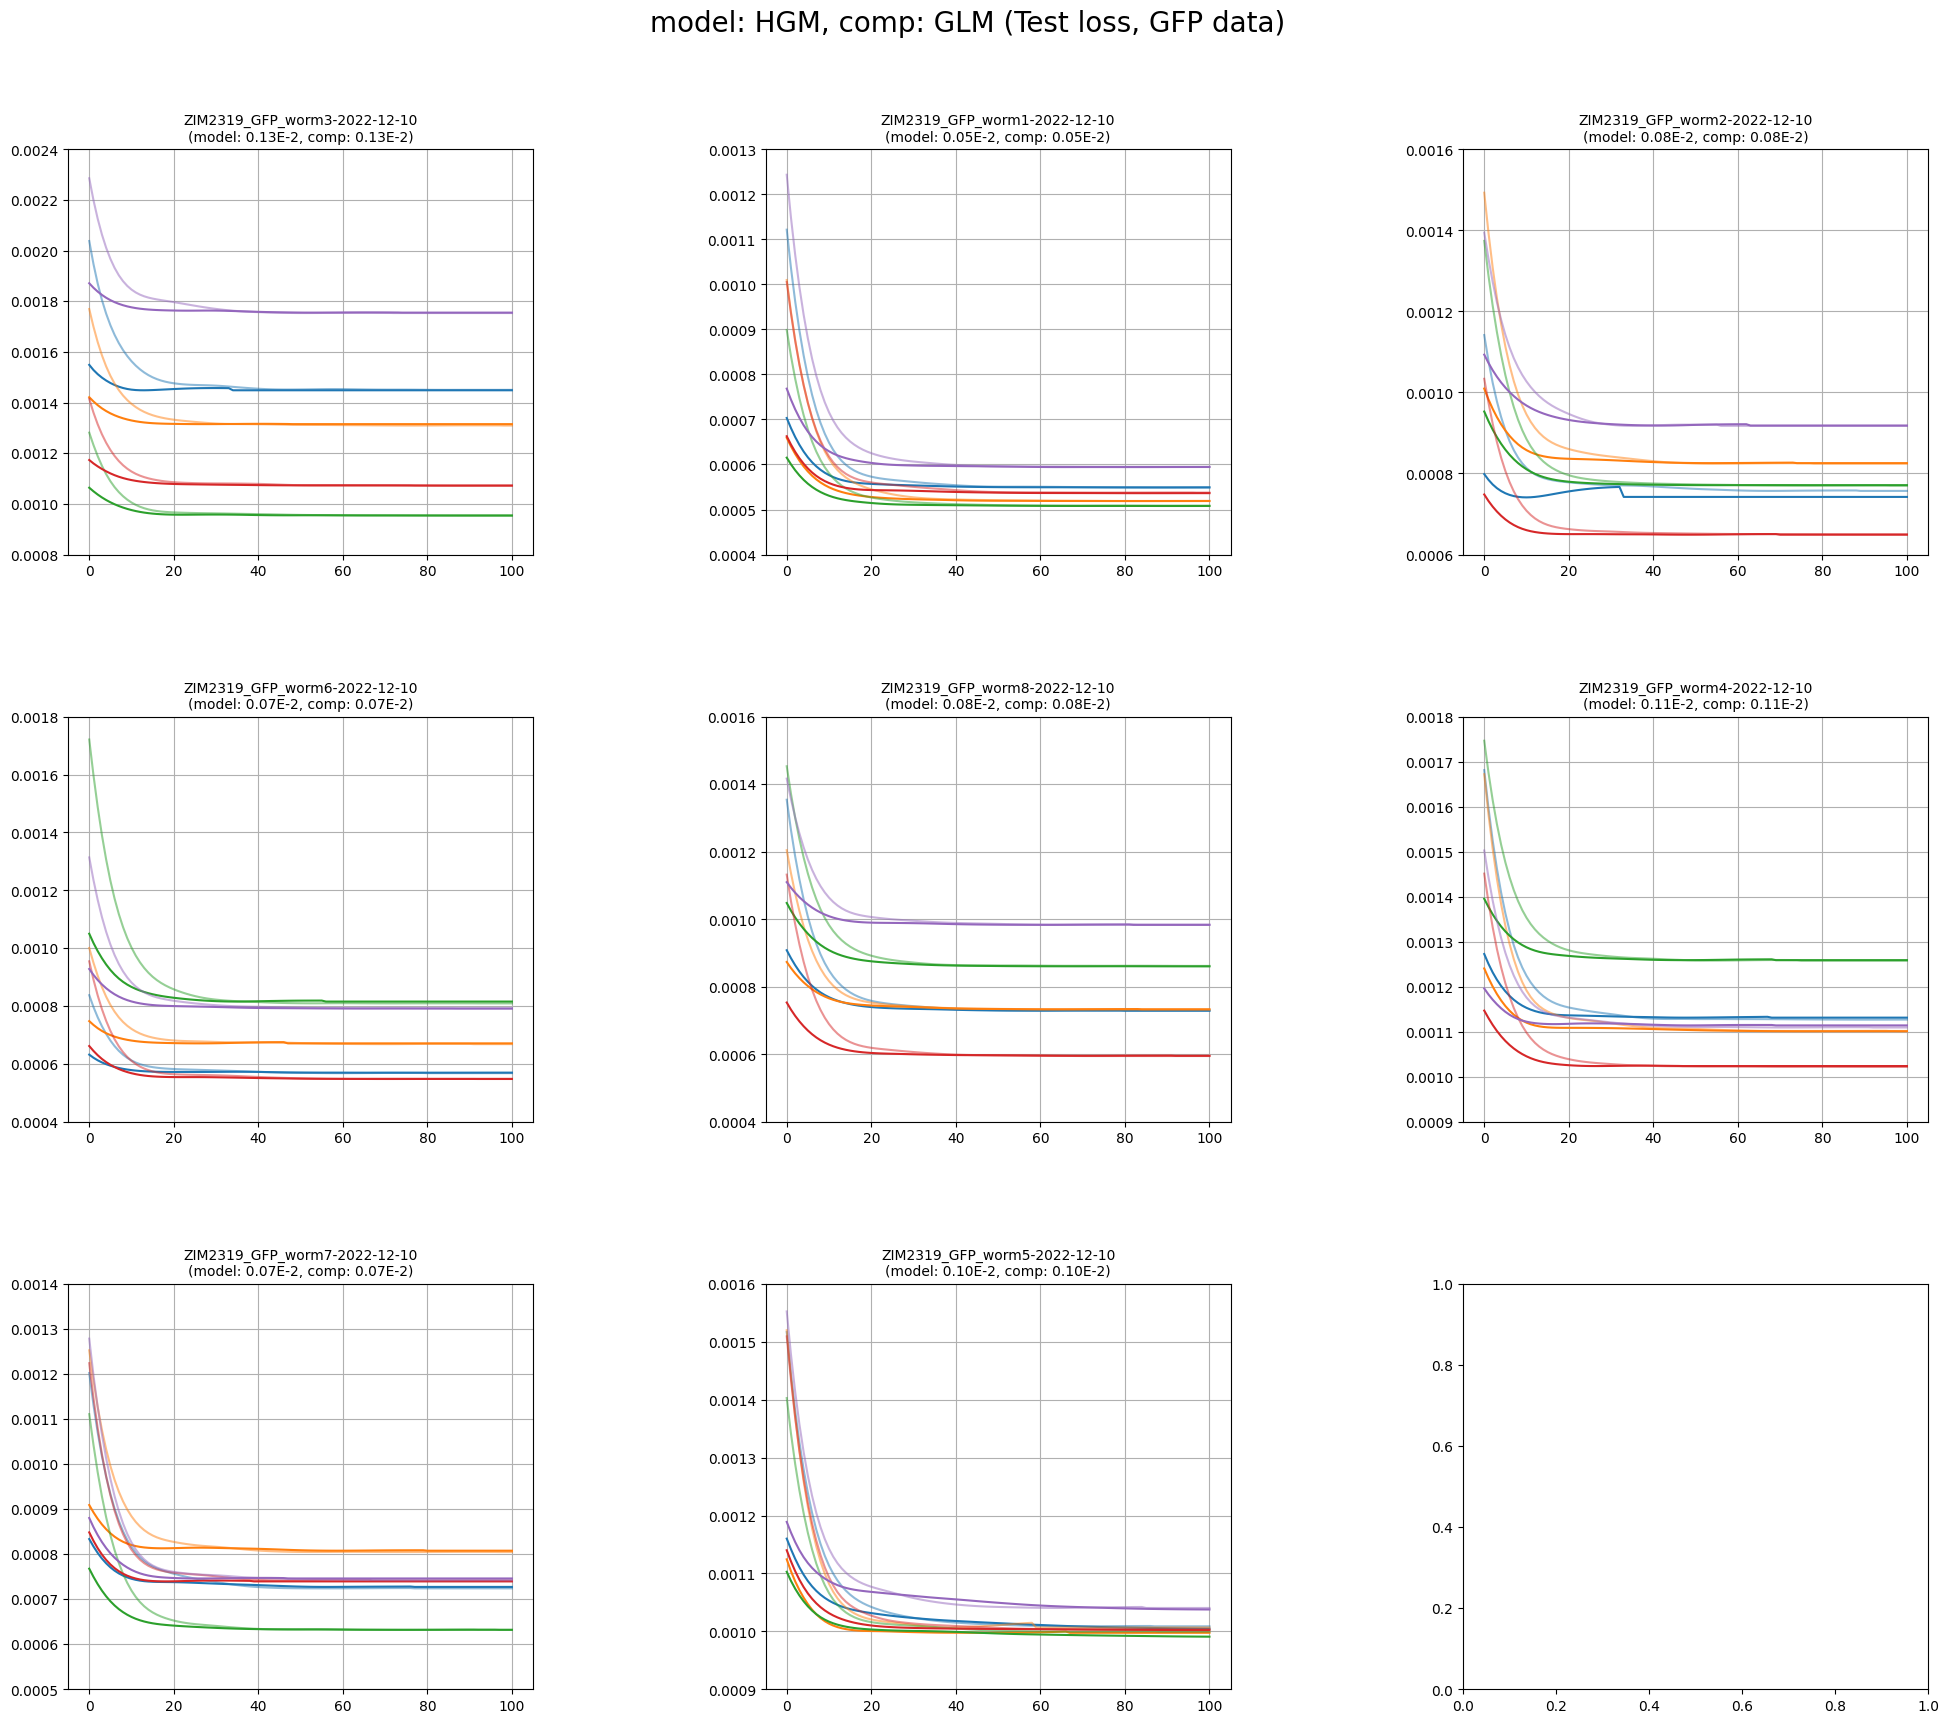

In [25]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_gfp, glm_models_losses_gfp, 'model: HGM, comp: GLM (Test loss, GFP data)')

# assemble

In [26]:
neurons_labels = [traces[i].columns for i in range(len(filenames))]

unique_labels = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels_filtered = [label for label in unique_labels if label != '' and label[-1] != '_']

neuron_scores = dict()
glm_models_avg_scores = [np.mean(scores, axis=0) for scores in glm_models_scores]
hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels, glm_models_avg_scores, hgm_models_avg_scores):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores.keys():
				neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores[label]
				neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

In [27]:
neurons_labels_gfp = [traces_gfp[i].columns for i in range(len(filenames_gfp))]

unique_labels_gfp = sorted(list(set([l for label in neurons_labels_gfp for l in label])))
unique_labels_filtered_gfp = [label for label in unique_labels_gfp if label != '' and label[-1] != '_']

neuron_scores_gfp = dict()
glm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in glm_models_scores_gfp]
hgm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in hgm_models_scores_gfp]
for label_list, score_glm_list, score_hgm_list in zip(neurons_labels_gfp, glm_models_avg_scores_gfp, hgm_models_avg_scores_gfp):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_glm_new = score_glm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores_gfp.keys():
				neuron_scores_gfp[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores_gfp[label]
				neuron_scores_gfp[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

# Plot

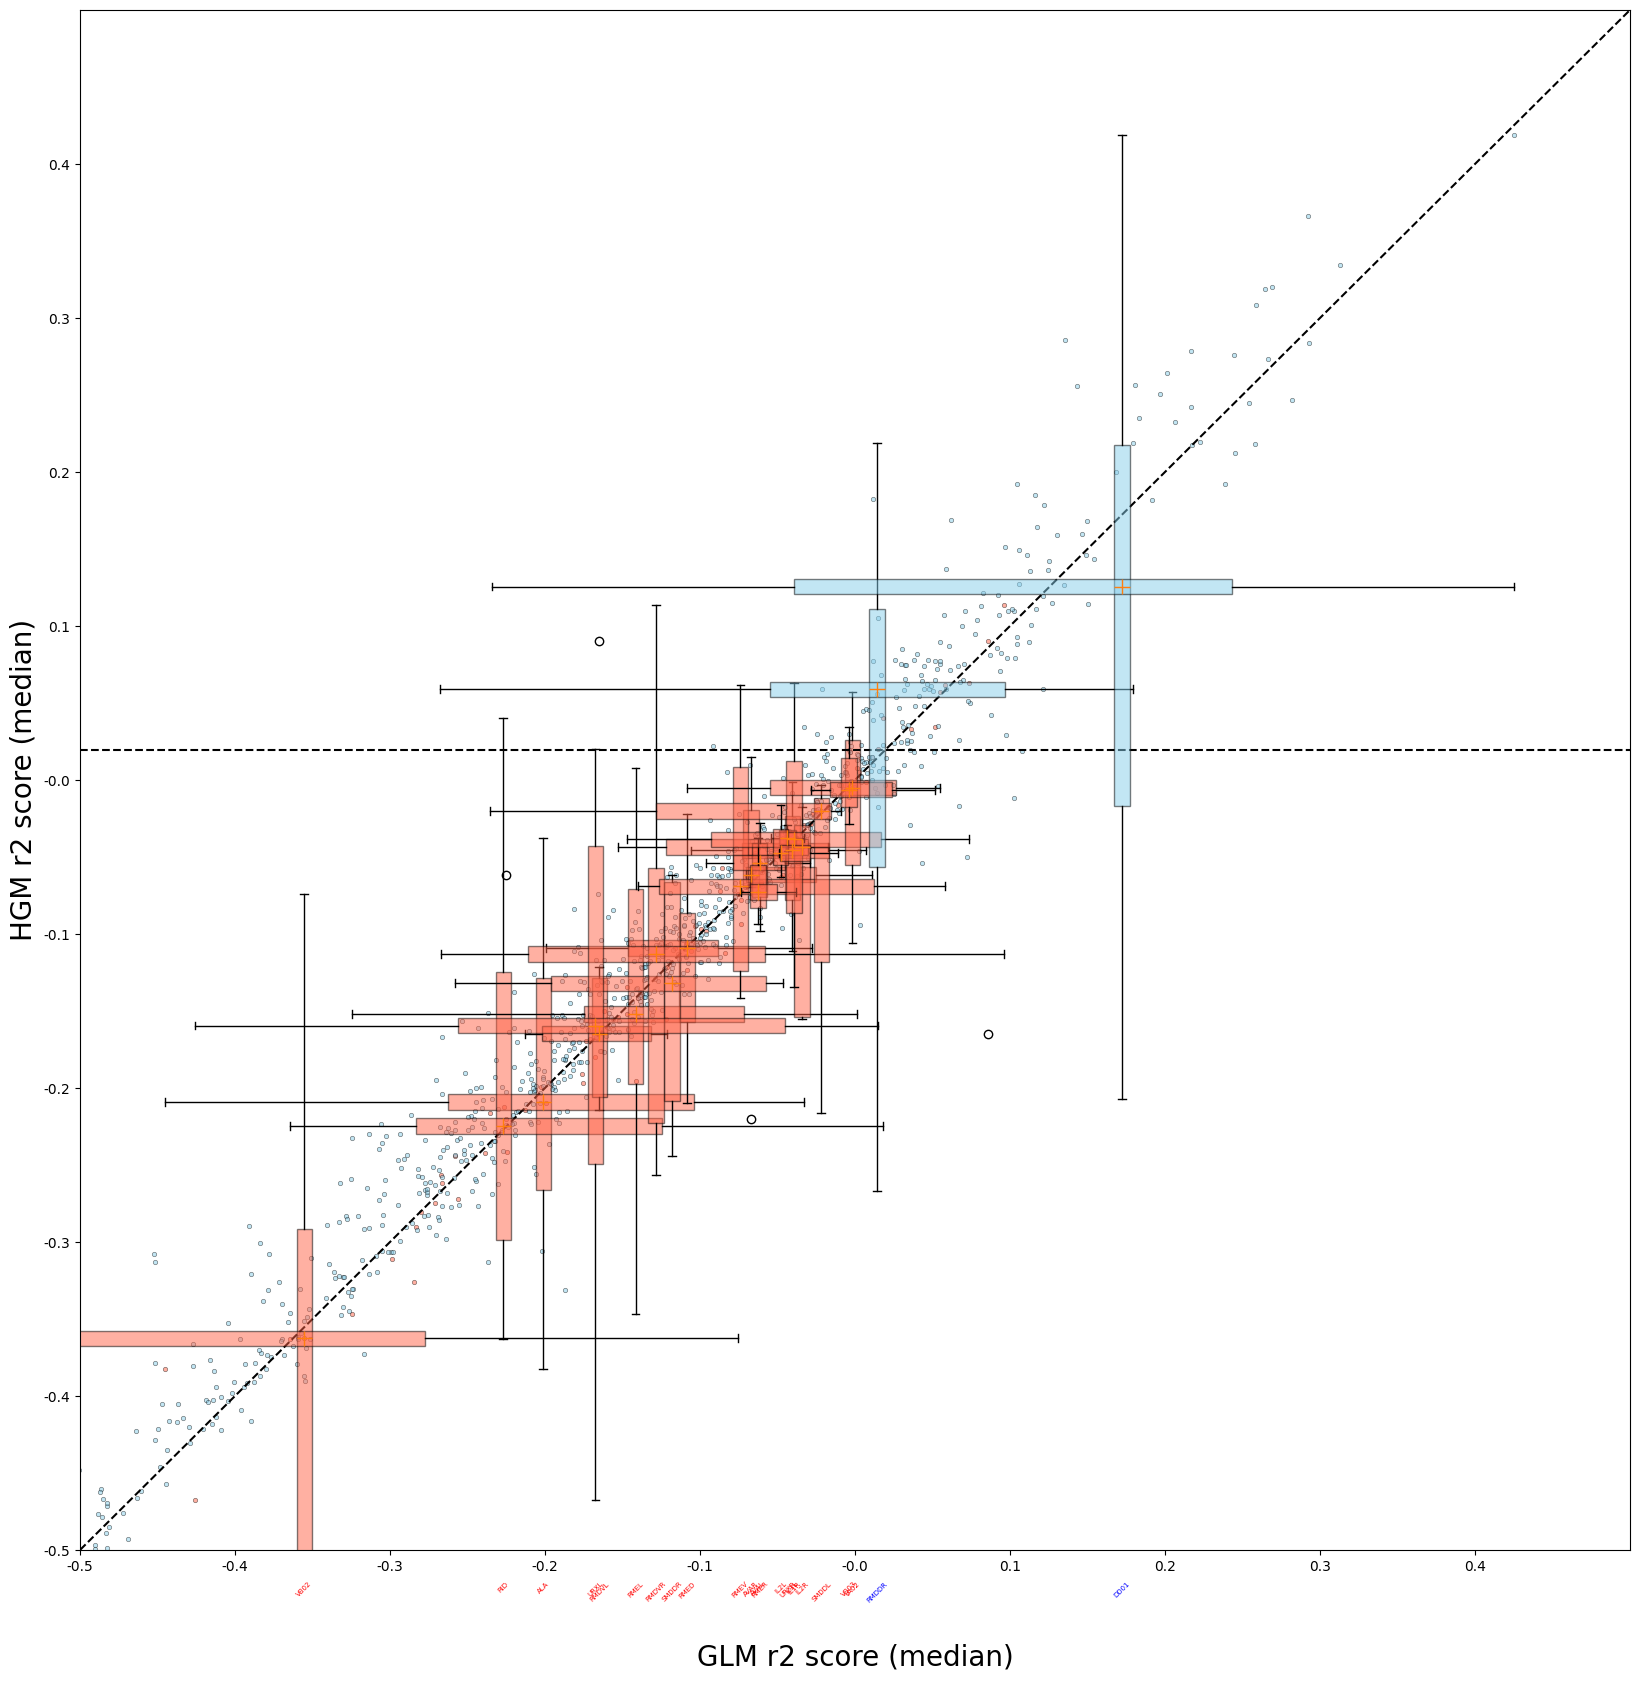

In [28]:
plot_utils.plot_performance_plot(neuron_scores, neuron_scores_gfp, save=False)

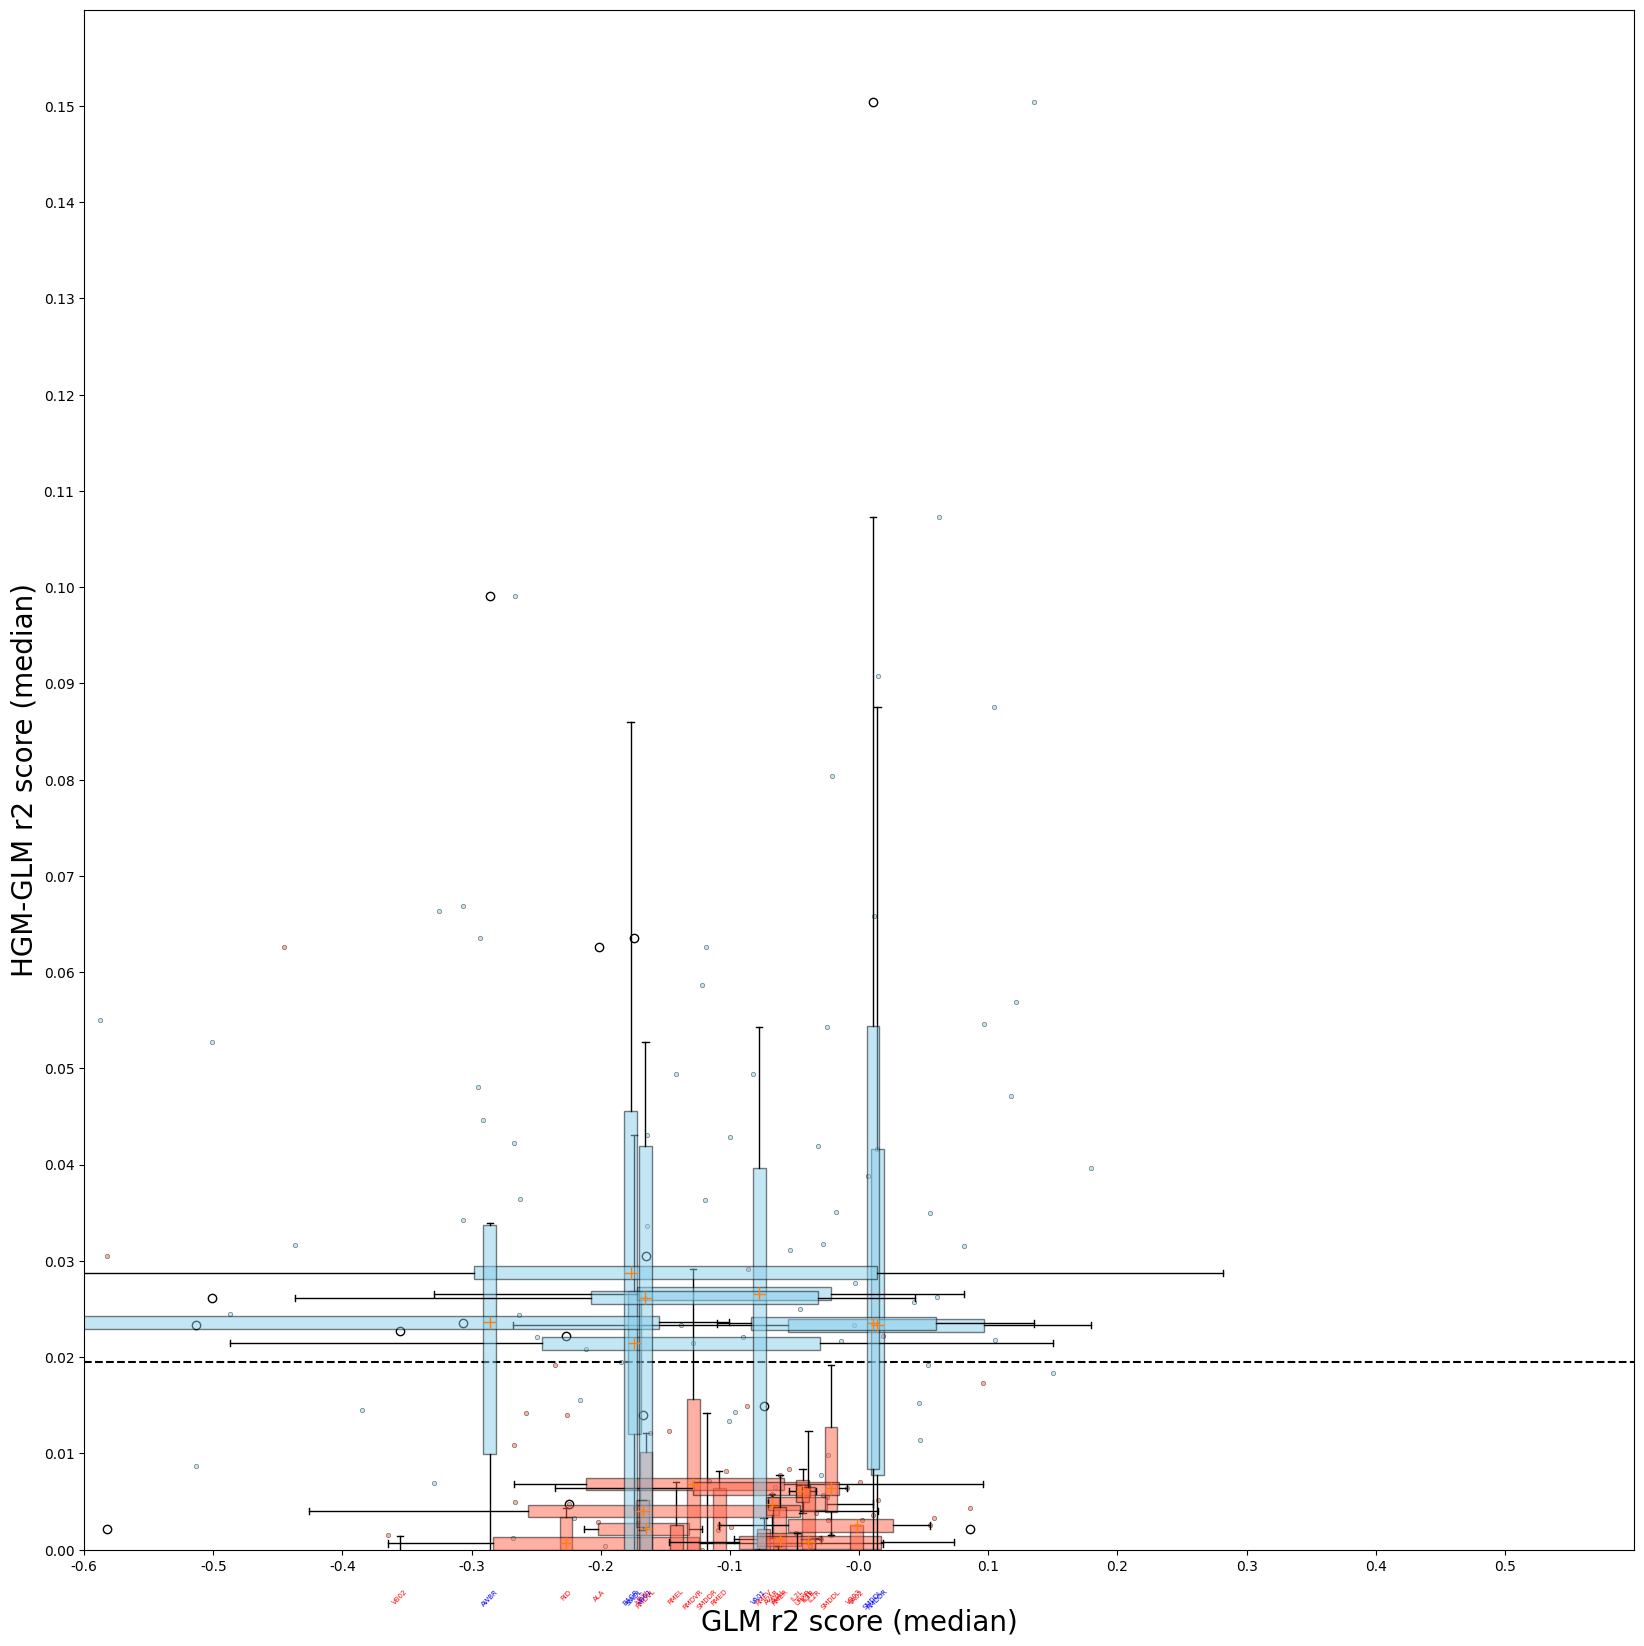

In [29]:
plot_utils.plot_improvement_plot(neuron_scores, neuron_scores_gfp, save=False)

# Final models

In [30]:
# todo

# some singular traces

In [31]:
residuals_pred_glm_df = pd.DataFrame(residuals_pred_glm, columns=neuronal_traces.columns)
heatmap = discrete_states['FWD'].values.reshape(-1, 1) * 0.1

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in residuals_pred_glm_df:
	if key != '':
		min_val, max_val = min(residuals_pred_glm_df[key]), max(residuals_pred_glm_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(residuals_pred_glm_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Predicted Signals (GLM)', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

NameError: name 'residuals_pred_glm' is not defined

In [ ]:
residuals_pred_hgm_df = pd.DataFrame(residuals_pred_hgm, columns=neuronal_traces.columns)
heatmap = discrete_states['FWD'].values.reshape(-1, 1) * 0.1

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in residuals_pred_hgm_df:
	if key != '':
		min_val, max_val = min(residuals_pred_hgm_df[key]), max(residuals_pred_hgm_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(residuals_pred_hgm_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Predicted Residuals (HGM)', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

plt.savefig('out/traces_single_residuals_predicted.png', dpi=300)

In [ ]:
signal_residual_df = pd.DataFrame(data=signal_residual, columns=neuronal_traces.columns)

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in signal_residual_df:
	if key != '':
		min_val, max_val = min(signal_residual_df[key]), max(signal_residual_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(signal_residual_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Actual Residuals', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

plt.savefig('out/traces_single_residuals.png', dpi=300)

In [ ]:
dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in neuronal_traces:
	if key != '':
		min_val, max_val = min(neuronal_traces[key]), max(neuronal_traces[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(neuronal_traces[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Traces', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

In [ ]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

ews = eigenworms.values
ds = discrete_states[selection].values
signal = neuronal_traces.values




cca_residual = CCA(n_components=5, scale=False)  # cca = CCA(n_components=5)
signal_residual_reduced, ews_reduced = cca_residual.fit_transform(signal_residual, ews)
signal_residual_reconstructed, ews_reconstructed = cca_residual.inverse_transform(signal_residual_reduced, ews_reduced)

signal_residual_indices = np.argsort(cca_residual.x_loadings_[:, 0])






fig, (ax_top, ax_3tom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(ds.T, aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("ds")
ax_top.set_yticks(np.arange(len(ds.T)))
ax_top.set_yticklabels(discrete_states[selection].columns, fontsize=8)
ax_top.set_xticks(np.arange(0, len(ds), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_3tom.imshow(np.clip(signal_residual.T[signal_residual_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_3tom.set_ylabel("Residual Neuronal activity")
ax_3tom.set_yticks(np.arange(len(signal_residual.T)))
ax_3tom.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_3tom.set_xticks(np.arange(0, len(signal_residual), 100))
fig.colorbar(im_bottom, ax=ax_3tom, orientation='vertical', fraction=0.05)
ax_3tom.grid(False)

plt.tight_layout()
plt.show()

In [ ]:


fig, (ax_1, ax_2, ax_3, ax_4) = plt.subplots(4, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [4, 1, 4, 4]})

im_1 = ax_1.imshow(np.clip(signal_residual.T[signal_residual_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_1.set_ylabel("residuals")
ax_1.set_yticks(np.arange(len(signal_residual.T)))
ax_1.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_1.set_xticks(np.arange(0, len(signal_residual), 100))
fig.colorbar(im_1, ax=ax_1, orientation='vertical', fraction=0.05)
ax_1.grid(False)

im_2 = ax_2.imshow(ds.T, aspect='auto', cmap='rainbow', interpolation='nearest')
ax_2.set_ylabel("ds")
ax_2.set_yticks(np.arange(len(ds.T)))
ax_2.set_yticklabels(discrete_states[selection].columns, fontsize=4)
ax_2.set_xticks(np.arange(0, len(ds), 100))
fig.colorbar(im_2, ax=ax_2, orientation='vertical', fraction=0.05)
ax_2.grid(False)

im_3 = ax_3.imshow(np.clip(residuals_pred_glm.T[signal_residual_indices], -0.2, 0.2), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_3.set_ylabel("predicted residuals (glm)")
ax_3.set_yticks(np.arange(len(residuals_pred_glm.T)))
ax_3.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_3.set_xticks(np.arange(0, len(residuals_pred_glm), 100))
fig.colorbar(im_3, ax=ax_3, orientation='vertical', fraction=0.05)
ax_3.grid(False)

im_4 = ax_4.imshow(np.clip(residuals_pred_hgm.T[signal_residual_indices], -0.2, 0.2), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_4.set_ylabel("predicted residuals (hgm)")
ax_4.set_yticks(np.arange(len(residuals_pred_hgm.T)))
ax_4.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_4.set_xticks(np.arange(0, len(residuals_pred_hgm), 100))
fig.colorbar(im_4, ax=ax_4, orientation='vertical', fraction=0.05)
ax_4.grid(False)

plt.savefig('out/traces_residuals_predicted.png', dpi=300)